### Next: Notebook 04 — Exploratory Electoral Participation Analysis
This is where we begin answering the research questions that motivated the project: how electoral participation has changed across Kenya's counties, which counties consistently record high or low participation, and how the October 2017 fresh presidential election differs from general elections.

Our proposed analysis will progress from national summaries to county comparisons, changes between elections, geographical patterns and visualisations.

One methodological rule will guide us throughout: we will not mix calculated turnout with valid-vote participation or treat unverified 2022 turnout as independently verified.

***Load the processed analytical dataset***

In [3]:

# Notebook 04 — Cell 1
# Load the validated county-level analytical dataset.
# Read-only: no existing files are modified.

from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project root from the notebook directory.
project_root = Path.cwd().resolve()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

data_path = (
    project_root
    / "data"
    / "processed"
    / "kenya_county_election_analytics.csv"
)

assert data_path.is_file(), (
    f"Analytical dataset not found: {data_path}"
)

# Load the dataset, preserving nullable integer fields.
elections_df = pd.read_csv(
    data_path,
    dtype={
        "analytical_registered_voters": "Int64",
        "analytical_valid_votes": "Int64",
        "analytical_ballots_cast": "Int64",
        "winner_votes": "Int64",
        "margin": "Int64",
        "county_key": "string"
    },
    parse_dates=["election_date"]
)

# Verify the expected structure.
assert elections_df.shape == (188, 20)

assert elections_df["election_id"].nunique() == 4

assert not elections_df.duplicated(
    ["election_id", "county_key"]
).any()

print("NOTEBOOK 04 — ANALYTICAL DATA LOADED")
print("=" * 65)
print("Dataset:", data_path.name)
print("Rows:", len(elections_df))
print("Columns:", len(elections_df.columns))

print("\nRECORDS BY ELECTION")
display(
    elections_df.groupby("election_id")
    .size()
    .reset_index(name="county_records")
)

print("\nDATASET PREVIEW")
display(elections_df.head())


NOTEBOOK 04 — ANALYTICAL DATA LOADED
Dataset: kenya_county_election_analytics.csv
Rows: 188
Columns: 20

RECORDS BY ELECTION


,election_id,county_records
0,2013_GENERAL,47
1,2017_AUG_GENERAL,47
2,2017_OCT_FRESH,47
3,2022_GENERAL,47



DATASET PREVIEW


,election_id,election_year,election_date,election_type,county,county_key,analytical_registered_voters,analytical_valid_votes,analytical_ballots_cast,calculated_turnout_pct,valid_vote_participation_pct,source_reported_turnout_pct,winner,winner_votes,runner_up,margin,county_validation_status,turnout_verification_status,validation_status,turnout_discrepancy_flag
0,2013_GENERAL,2013,2013-03-04,General Election,Mombasa,MOMBASA,413069,269314,272318,65.93,65.20,66.62,Raila Odinga,189985,Uhuru Kenyatta,125192,PARTIALLY_RECONCILED,IEBC_NUMBER_VOTED,PARTIALLY_RECONCILED,False
1,2013_GENERAL,2013,2013-03-04,General Election,Kwale,KWALE,175572,124626,125601,71.54,70.98,72.00,Raila Odinga,101407,Uhuru Kenyatta,83774,PARTIALLY_RECONCILED,IEBC_NUMBER_VOTED,PARTIALLY_RECONCILED,False
2,2013_GENERAL,2013,2013-03-04,General Election,Kilifi,KILIFI,336410,215792,218174,64.85,64.15,64.91,Raila Odinga,182708,Uhuru Kenyatta,159322,PARTIALLY_RECONCILED,IEBC_NUMBER_VOTED,PARTIALLY_RECONCILED,False
3,2013_GENERAL,2013,2013-03-04,General Election,Tana River,TANARIVER,79641,64080,64589,81.10,80.46,81.29,Raila Odinga,39666,Uhuru Kenyatta,17247,PARTIALLY_RECONCILED,IEBC_NUMBER_VOTED,PARTIALLY_RECONCILED,False
4,2013_GENERAL,2013,2013-03-04,General Election,Lamu,LAMU,52359,43534,44171,84.36,83.15,84.38,Raila Odinga,22962,Uhuru Kenyatta,5285,PARTIALLY_RECONCILED,IEBC_NUMBER_VOTED,PARTIALLY_RECONCILED,False


**Notebook 04 — Cell 2: National electoral participation overview**
Our first objective is to establish how participation differs across the four election events.

There is an important methodological consideration: national participation rates must be weighted by registered voters, rather than calculated as simple averages of county percentages.

We will also distinguish between complete and partial county coverage.

***Election	            | Calculated turnout	    | Valid-vote participation	| Interpretation***
- 2013 General	        | Available for 47 counties	| Available for 47 counties	| Partially reconciled source data
- August 2017 General	| Available for 45 counties	| Available for 45 counties	| Excludes Kisumu and Turkana
- October 2017 Fresh	| Available for 47 counties	| Available for 47 counties	| Distinct electoral event
- 2022 General	        | Unavailable	            | Available for 47 counties	| ELOG-derived, independently unverified

For August 2017, we will calculate participation using only the registered voters belonging to the 45 counties with available vote counts. We will not present this as a complete national turnout rate.

In [10]:
# Calculate weighted electoral participation by election event.
# Missing county values are excluded together with their denominators.
# No source files or analytical records are modified.

participation_summary = []

for election_id, group in elections_df.groupby(
    "election_id", sort=False
):

    total_counties = group["county"].nunique()

    # Registered voters across all 47 counties
    total_registered = group[
        "analytical_registered_voters"
    ].sum()

    # Ballots-cast turnout: use only counties with available
    # ballots-cast and registration figures.
    turnout_subset = group.dropna(
        subset=[
            "analytical_registered_voters",
            "analytical_ballots_cast"
        ]
    )

    turnout_counties = len(turnout_subset)

    turnout_registered = turnout_subset[
        "analytical_registered_voters"
    ].sum()

    turnout_ballots = turnout_subset[
        "analytical_ballots_cast"
    ].sum()

    calculated_turnout = (
        turnout_ballots / turnout_registered * 100
        if turnout_counties > 0 and turnout_registered > 0
        else np.nan
    )

    # Valid-vote participation: independently establish
    # the counties eligible for this measure.
    valid_subset = group.dropna(
        subset=[
            "analytical_registered_voters",
            "analytical_valid_votes"
        ]
    )

    valid_counties = len(valid_subset)

    valid_registered = valid_subset[
        "analytical_registered_voters"
    ].sum()

    valid_votes = valid_subset[
        "analytical_valid_votes"
    ].sum()

    valid_participation = (
        valid_votes / valid_registered * 100
        if valid_counties > 0 and valid_registered > 0
        else np.nan
    )

    participation_summary.append({
        "election_id": election_id,
        "total_counties": total_counties,
        "total_registered_voters": total_registered,
        "turnout_counties": turnout_counties,
        "turnout_registered_voters": (
            turnout_registered if turnout_counties else np.nan
        ),
        "ballots_cast": (
            turnout_ballots if turnout_counties else np.nan
        ),
        "weighted_turnout_pct": calculated_turnout,
        "valid_vote_counties": valid_counties,
        "valid_vote_registered_voters": valid_registered,
        "valid_votes": valid_votes,
        "weighted_valid_participation_pct": valid_participation
    })


national_participation_df = pd.DataFrame(
    participation_summary
)

# Add clear coverage labels.
national_participation_df["turnout_coverage"] = (
    national_participation_df.apply(
        lambda row: (
            "COMPLETE_47_COUNTIES"
            if row["turnout_counties"] == 47
            else "UNAVAILABLE"
            if row["turnout_counties"] == 0
            else f"PARTIAL_{int(row['turnout_counties'])}_COUNTIES"
        ),
        axis=1
    )
)

national_participation_df["valid_vote_coverage"] = (
    national_participation_df.apply(
        lambda row: (
            "COMPLETE_47_COUNTIES"
            if row["valid_vote_counties"] == 47
            else f"PARTIAL_{int(row['valid_vote_counties'])}_COUNTIES"
        ),
        axis=1
    )
)

# Round only the percentage fields for presentation.
display_columns = [
    "election_id",
    "total_counties",
    "total_registered_voters",
    "turnout_counties",
    "weighted_turnout_pct",
    "turnout_coverage",
    "valid_vote_counties",
    "weighted_valid_participation_pct",
    "valid_vote_coverage"
]

print("NATIONAL ELECTORAL PARTICIPATION OVERVIEW")
print("=" * 65)

display(
    national_participation_df[
        display_columns
    ].round(2)
)

print("\nPARTICIPATION COUNTS AND DENOMINATORS")

display(
    national_participation_df[
        [
            "election_id",
            "turnout_registered_voters",
            "ballots_cast",
            "valid_vote_registered_voters",
            "valid_votes"
        ]
    ]
)


NATIONAL ELECTORAL PARTICIPATION OVERVIEW


,election_id,total_counties,total_registered_voters,turnout_counties,weighted_turnout_pct,turnout_coverage,valid_vote_counties,weighted_valid_participation_pct,valid_vote_coverage
0,2013_GENERAL,47,14386144,47,85.69,COMPLETE_47_COUNTIES,47,84.93,COMPLETE_47_COUNTIES
1,2017_AUG_GENERAL,47,19607064,45,77.62,PARTIAL_45_COUNTIES,45,77.20,PARTIAL_45_COUNTIES
2,2017_OCT_FRESH,47,19607030,47,39.03,COMPLETE_47_COUNTIES,47,38.84,COMPLETE_47_COUNTIES
3,2022_GENERAL,47,22110015,0,NaN,UNAVAILABLE,47,64.26,COMPLETE_47_COUNTIES



PARTICIPATION COUNTS AND DENOMINATORS


,election_id,turnout_registered_voters,ballots_cast,valid_vote_registered_voters,valid_votes
0,2013_GENERAL,14386144.0,12327700.0,14386144,12218735
1,2017_AUG_GENERAL,18876036.0,14651693.0,18876036,14571915
2,2017_OCT_FRESH,19607030.0,7652568.0,19607030,7614866
3,2022_GENERAL,NaN,NaN,22110015,14207149


### Key findings
**2013** recorded the highest calculated turnout in our dataset, at 85.69%. The difference between calculated turnout and valid-vote participation was 0.76 percentage points, reflecting the distinction between ballots cast and valid votes.

**August 2017** recorded 77.62% calculated turnout across 45 counties. This is approximately 8.07 percentage points below the 2013 figure, but it is not a like-for-like national comparison because Kisumu and Turkana are excluded.

**October 2017** recorded 39.03% calculated turnout, substantially below August 2017. The two elections took place in different electoral circumstances, so this difference should be examined as an event-specific participation change rather than treated as an ordinary election-cycle trend.

**2022** recorded 64.26% valid-vote participation, based on the ELOG-derived county figures. This is not directly equivalent to ballots-cast turnout and remains independently unverified at county level.

Between 2013 and 2022, the county registration totals increased by approximately 7.72 million voters, or 53.7%.

However, we should distinguish the expansion of the registered electorate from the proportion that actually participates.

### Investigate registration growth and source coverage
Before drawing stronger conclusions, let's quantify registration growth and inspect the county coverage underlying our August 2017 participation calculation.

In [15]:

# Notebook 04 — Cell 3
# Investigate voter registration growth and participation coverage.
# Diagnostic only — no files are modified.

registration_review = national_participation_df[
    [
        "election_id",
        "total_registered_voters",
        "total_counties",
        "turnout_counties",
        "valid_vote_counties"
    ]
].copy()

# Calculate changes relative to the preceding election event.
registration_review["registered_change"] = (
    registration_review["total_registered_voters"].diff()
)

registration_review["registered_change_pct"] = (
    registration_review["total_registered_voters"]
    .pct_change()
    * 100
)

print("REGISTRATION GROWTH BY ELECTION EVENT")
print("=" * 65)

display(registration_review.round(2))


# Compare the three general elections separately.
general_registration = registration_review.loc[
    registration_review["election_id"].isin([
        "2013_GENERAL",
        "2017_AUG_GENERAL",
        "2022_GENERAL"
    ])
].copy()

general_registration["change_from_previous_general"] = (
    general_registration["total_registered_voters"].diff()
)

general_registration["growth_from_previous_general_pct"] = (
    general_registration["total_registered_voters"]
    .pct_change()
    * 100
)

print("\nGENERAL ELECTION REGISTRATION GROWTH")
display(general_registration.round(2))


# Identify counties excluded from August 2017 turnout.
august_missing = elections_df.loc[
    elections_df["election_id"].eq("2017_AUG_GENERAL")
    & elections_df["analytical_ballots_cast"].isna(),
    [
        "county",
        "analytical_registered_voters",
        "county_validation_status"
    ]
].copy()

print("\nAUGUST 2017 COUNTIES EXCLUDED FROM TURNOUT")
display(august_missing)

print(
    "\nRegistered voters excluded:",
    august_missing["analytical_registered_voters"].sum()
)


# Verify coverage of the August 2017 denominator.
august_total_registered = registration_review.loc[
    registration_review["election_id"].eq("2017_AUG_GENERAL"),
    "total_registered_voters"
].iloc[0]

august_covered_registered = national_participation_df.loc[
    national_participation_df["election_id"].eq("2017_AUG_GENERAL"),
    "turnout_registered_voters"
].iloc[0]

coverage_pct = (
    august_covered_registered / august_total_registered * 100
)

print(
    f"\nAugust 2017 registration coverage: {coverage_pct:.2f}%"
)


REGISTRATION GROWTH BY ELECTION EVENT


,election_id,total_registered_voters,total_counties,turnout_counties,valid_vote_counties,registered_change,registered_change_pct
0,2013_GENERAL,14386144,47,47,47,NaN,NaN
1,2017_AUG_GENERAL,19607064,47,45,45,5220920.0,36.29
2,2017_OCT_FRESH,19607030,47,47,47,-34.0,-0.00
3,2022_GENERAL,22110015,47,0,47,2502985.0,12.77



GENERAL ELECTION REGISTRATION GROWTH


,election_id,total_registered_voters,total_counties,turnout_counties,valid_vote_counties,registered_change,registered_change_pct,change_from_previous_general,growth_from_previous_general_pct
0,2013_GENERAL,14386144,47,47,47,NaN,NaN,NaN,NaN
1,2017_AUG_GENERAL,19607064,47,45,45,5220920.0,36.29,5220920.0,36.29
3,2022_GENERAL,22110015,47,0,47,2502985.0,12.77,2502951.0,12.77



AUGUST 2017 COUNTIES EXCLUDED FROM TURNOUT


,county,analytical_registered_voters,county_validation_status
69,Turkana,191435,UNRESOLVED_SOURCE_DIFFERENCE
88,Kisumu,539593,INTERNAL_SOURCE_INCONSISTENCY



Registered voters excluded: 731028

August 2017 registration coverage: 96.27%


**Cell 3 has produced two important findings:** voter registration increased substantially between general elections, and our August 2017 turnout estimate covers 96.27% of the registered electorate.

However, the results also highlight a source-reconciliation issue we should resolve before progressing to county-level analysis.

### Reconcile 2013 registration totals
Let's compare the 2013 registration figures in our processed dataset against the original official county-level extraction saved in Notebook 02.

This will help us determine whether the 2,637-voter difference was introduced during data preparation or already existed in the extracted IEBC county figures.

In [19]:

# Notebook 04 — Cell 4
# Investigate the 2013 registration difference.
# Diagnostic only — no source files or datasets are modified.

official_2013_path = (
    project_root
    / "data"
    / "interim"
    / "iebc_2013_county_official.csv"
)

assert official_2013_path.is_file(), (
    f"Official 2013 extraction not found: {official_2013_path}"
)

official_2013 = pd.read_csv(official_2013_path)

analytical_2013 = elections_df.loc[
    elections_df["election_id"].eq("2013_GENERAL"),
    [
        "county",
        "county_key",
        "analytical_registered_voters"
    ]
].copy()

# Reuse the standardised county-key method from Notebook 03.
def normalize_county_key(value):
    return "".join(
        char for char in str(value).upper()
        if char.isalnum()
    )

official_2013["normalized_county_key"] = (
    official_2013["county_key"]
    .map(normalize_county_key)
)

analytical_2013["normalized_county_key"] = (
    analytical_2013["county_key"]
    .map(normalize_county_key)
)

# Confirm uniqueness before joining.
assert not official_2013[
    "normalized_county_key"
].duplicated().any()

assert not analytical_2013[
    "normalized_county_key"
].duplicated().any()

registration_comparison = analytical_2013.merge(
    official_2013[
        [
            "normalized_county_key",
            "registered_biometric",
            "registered_non_biometric",
            "registered_total"
        ]
    ],
    on="normalized_county_key",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Convert comparison fields to numeric.
numeric_columns = [
    "analytical_registered_voters",
    "registered_biometric",
    "registered_non_biometric",
    "registered_total"
]

for col in numeric_columns:
    registration_comparison[col] = pd.to_numeric(
        registration_comparison[col],
        errors="raise"
    )

# Compare analytical registration with official county totals.
registration_comparison["registration_difference"] = (
    registration_comparison["analytical_registered_voters"]
    - registration_comparison["registered_total"]
)

print("2013 REGISTRATION RECONCILIATION")
print("=" * 65)

print("\nCOUNTY MATCH STATUS")
display(registration_comparison["_merge"].value_counts())

print("\nREGISTRATION TOTALS")

total_summary = pd.DataFrame({
    "measure": [
        "IEBC extracted biometric registration",
        "IEBC extracted non-biometric registration",
        "IEBC extracted total registration",
        "Analytical county registration",
        "Previously recorded IEBC national benchmark"
    ],
    "registered_voters": [
        registration_comparison["registered_biometric"].sum(),
        registration_comparison["registered_non_biometric"].sum(),
        registration_comparison["registered_total"].sum(),
        registration_comparison[
            "analytical_registered_voters"
        ].sum(),
        14388781
    ]
})

display(total_summary)

print("\nCOUNTIES WITH REGISTRATION DIFFERENCES")

differences = registration_comparison.loc[
    registration_comparison["registration_difference"].ne(0),
    [
        "county",
        "analytical_registered_voters",
        "registered_biometric",
        "registered_non_biometric",
        "registered_total",
        "registration_difference"
    ]
]

if differences.empty:
    print("No county-level differences identified.")
else:
    display(differences.sort_values(
        "registration_difference",
        key=lambda s: s.abs(),
        ascending=False
    ))

print("\nTOTAL ANALYTICAL MINUS EXTRACTED IEBC DIFFERENCE")
print(registration_comparison["registration_difference"].sum())


2013 REGISTRATION RECONCILIATION

COUNTY MATCH STATUS


_merge
both          47
left_only      0
right_only     0
Name: count, dtype: int64


REGISTRATION TOTALS


,measure,registered_voters
0,IEBC extracted biometric registration,14349908
1,IEBC extracted non-biometric registration,36236
2,IEBC extracted total registration,14386144
3,Analytical county registration,14386144
4,Previously recorded IEBC national benchmark,14388781



COUNTIES WITH REGISTRATION DIFFERENCES
No county-level differences identified.

TOTAL ANALYTICAL MINUS EXTRACTED IEBC DIFFERENCE
0


### County-level participation distribution
We can now begin investigating a central question of this project:

How much does electoral participation vary between Kenya's counties, and how does that variation change across election events?

In [23]:

# Notebook 04 — Cell 5
# Examine the distribution of calculated county turnout.
# This is a descriptive analysis; no files are modified.

# Use only counties with available calculated turnout.
county_turnout = elections_df.loc[
    elections_df["calculated_turnout_pct"].notna(),
    [
        "election_id",
        "county",
        "calculated_turnout_pct",
        "analytical_registered_voters",
        "county_validation_status"
    ]
].copy()

# Descriptive statistics by election event.
turnout_distribution = (
    county_turnout
    .groupby("election_id")["calculated_turnout_pct"]
    .agg(
        counties="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max",
        standard_deviation="std"
    )
    .reset_index()
)

turnout_distribution["range_pp"] = (
    turnout_distribution["maximum"]
    - turnout_distribution["minimum"]
)

print("COUNTY TURNOUT DISTRIBUTION BY ELECTION")
print("=" * 65)

display(turnout_distribution.round(2))


# Identify the five highest-turnout counties per event.
highest_turnout = (
    county_turnout
    .sort_values(
        ["election_id", "calculated_turnout_pct"],
        ascending=[True, False]
    )
    .groupby("election_id", group_keys=False)
    .head(5)
)

print("\nFIVE HIGHEST-TURNOUT COUNTIES PER ELECTION")

display(
    highest_turnout[
        ["election_id", "county", "calculated_turnout_pct"]
    ].round(2)
)


# Identify the five lowest-turnout counties per event.
lowest_turnout = (
    county_turnout
    .sort_values(
        ["election_id", "calculated_turnout_pct"],
        ascending=[True, True]
    )
    .groupby("election_id", group_keys=False)
    .head(5)
)

print("\nFIVE LOWEST-TURNOUT COUNTIES PER ELECTION")

display(
    lowest_turnout[
        ["election_id", "county", "calculated_turnout_pct"]
    ].round(2)
)


# Verify coverage.
print("\nCOUNTIES INCLUDED IN THIS ANALYSIS")

display(
    county_turnout.groupby("election_id")
    .size()
    .reset_index(name="county_count")
)


COUNTY TURNOUT DISTRIBUTION BY ELECTION


,election_id,counties,mean,median,minimum,maximum,standard_deviation,range_pp
0,2013_GENERAL,47,85.78,87.28,64.85,93.94,6.37,29.09
1,2017_AUG_GENERAL,45,77.75,78.42,59.45,87.15,5.98,27.70
2,2017_OCT_FRESH,47,37.53,32.10,0.00,85.17,28.11,85.17



FIVE HIGHEST-TURNOUT COUNTIES PER ELECTION


,election_id,county,calculated_turnout_pct
42,2013_GENERAL,Homa Bay,93.94
17,2013_GENERAL,Nyandarua,93.50
20,2013_GENERAL,Murang'a,93.37
18,2013_GENERAL,Nyeri,92.71
40,2013_GENERAL,Siaya,92.32
66,2017_AUG_GENERAL,Kirinyaga,87.15
67,2017_AUG_GENERAL,Murang'a,86.88
65,2017_AUG_GENERAL,Nyeri,86.82
64,2017_AUG_GENERAL,Nyandarua,86.56
89,2017_AUG_GENERAL,Homa Bay,84.71



FIVE LOWEST-TURNOUT COUNTIES PER ELECTION


,election_id,county,calculated_turnout_pct
2,2013_GENERAL,Kilifi,64.85
0,2013_GENERAL,Mombasa,65.93
1,2013_GENERAL,Kwale,71.54
22,2013_GENERAL,Turkana,75.35
6,2013_GENERAL,Garissa,79.75
47,2017_AUG_GENERAL,Mombasa,59.45
49,2017_AUG_GENERAL,Kilifi,64.91
48,2017_AUG_GENERAL,Kwale,66.35
53,2017_AUG_GENERAL,Garissa,69.86
51,2017_AUG_GENERAL,Lamu,71.80



COUNTIES INCLUDED IN THIS ANALYSIS


,election_id,county_count
0,2013_GENERAL,47
1,2017_AUG_GENERAL,45
2,2017_OCT_FRESH,47


**Three observations stand out.**

First, county participation was comparatively consistent in 2013 and August 2017. Their standard deviations were approximately six percentage points, although August 2017 excludes two counties.

Second, October 2017 exhibited exceptional variation. Its standard deviation was 28.11 percentage points, more than four times the August 2017 figure. The median of 32.10% was also considerably below the mean of 37.53%, indicating that higher-turnout counties pulled the average upward.

Third, some counties recorded virtually no participation in October 2017. Siaya and Homa Bay recorded 0.00% in the analytical dataset, while Kisumu recorded 0.17%.

We should verify whether the 0.00% values represent genuinely zero recorded ballots or very small values rounded to two decimal places before describing them as complete non-participation.

**Murang'a, Nyeri and Nyandarua**

These counties appear consistently among the highest-turnout counties in all three election events. Murang'a recorded 85.17% even in October 2017.


**Kisumu, Siaya and Homa Bay**

These counties recorded exceptionally low turnout in October 2017. Homa Bay was among the highest-turnout counties in 2013, making its change particularly noteworthy.


**Mombasa and Kilifi**

Both counties appear among the lowest-turnout counties in 2013 and August 2017, suggesting a recurring pattern worth investigating.

### Investigate extreme October 2017 turnout values
Before comparing individual county changes, let's examine the underlying registration and ballot counts for the lowest-turnout counties.

This will distinguish actual zero-ballot records from percentages that round to zero.

In [28]:

# Notebook 04 — Cell 6
# Investigate extremely low October 2017 turnout values.
# Read-only diagnostic; no source files are modified.

october_df = elections_df.loc[
    elections_df["election_id"].eq("2017_OCT_FRESH")
].copy()

# Recalculate turnout at greater precision.
october_df["turnout_unrounded_pct"] = (
    october_df["analytical_ballots_cast"]
    / october_df["analytical_registered_voters"]
    * 100
)

# Select counties with turnout below 5%.
extreme_low_turnout = october_df.loc[
    october_df["turnout_unrounded_pct"] < 5,
    [
        "county",
        "analytical_registered_voters",
        "analytical_valid_votes",
        "analytical_ballots_cast",
        "turnout_unrounded_pct",
        "calculated_turnout_pct",
        "county_validation_status"
    ]
].sort_values("turnout_unrounded_pct")

print("OCTOBER 2017 — COUNTIES BELOW 5% TURNOUT")
print("=" * 65)

display(extreme_low_turnout)


# Inspect counties displaying 0.00% turnout.
zero_display_counties = october_df.loc[
    october_df["calculated_turnout_pct"].eq(0),
    [
        "county",
        "analytical_registered_voters",
        "analytical_valid_votes",
        "analytical_ballots_cast",
        "turnout_unrounded_pct"
    ]
]

print("\nCOUNTIES DISPLAYING 0.00% TURNOUT")
display(zero_display_counties)


# Count exact zero-ballot records.
exact_zero_ballots = october_df.loc[
    october_df["analytical_ballots_cast"].eq(0)
]

print("\nEXACT ZERO-BALLOT COUNTIES")
print("Count:", len(exact_zero_ballots))

display(
    exact_zero_ballots[
        [
            "county",
            "analytical_registered_voters",
            "analytical_ballots_cast"
        ]
    ]
)


# Check consistency between recorded and calculated turnout.
october_df["turnout_rounding_difference"] = (
    october_df["calculated_turnout_pct"]
    - october_df["turnout_unrounded_pct"].round(2)
)

print("\nTURNOUT ROUNDING CONSISTENCY")

print(
    "Maximum absolute difference:",
    october_df["turnout_rounding_difference"].abs().max()
)


OCTOBER 2017 — COUNTIES BELOW 5% TURNOUT


,county,analytical_registered_voters,analytical_valid_votes,analytical_ballots_cast,turnout_unrounded_pct,calculated_turnout_pct,county_validation_status
134,Siaya,457957,0,0,0.0,0.00,MATCHED
136,Homa Bay,476932,0,0,0.0,0.00,MATCHED
135,Kisumu,539597,899,904,0.167532,0.17,MATCHED
131,Vihiga,272415,10584,10832,3.976286,3.98,MATCHED
110,Makueni,423434,19409,19633,4.636614,4.64,MATCHED



COUNTIES DISPLAYING 0.00% TURNOUT


,county,analytical_registered_voters,analytical_valid_votes,analytical_ballots_cast,turnout_unrounded_pct
134,Siaya,457957,0,0,0.0
136,Homa Bay,476932,0,0,0.0



EXACT ZERO-BALLOT COUNTIES
Count: 2


,county,analytical_registered_voters,analytical_ballots_cast
134,Siaya,457957,0
136,Homa Bay,476932,0



TURNOUT ROUNDING CONSISTENCY
Maximum absolute difference: 0.0


First, Siaya and Homa Bay have exactly zero ballots recorded in our reconciled October 2017 county dataset. This is not a rounding effect. Both ELOG and the extracted IEBC figures matched during our reconciliation.

However, this establishes what the source records report, not necessarily that no individual attempted to vote in those counties. We should retain that distinction in our final interpretation.

Second, Kisumu recorded just 904 ballots cast against 539,597 registered voters. This produced a calculated turnout of 0.17%.

Third, the turnout calculation is internally consistent. The maximum difference between the stored percentages and independently recalculated values was zero.

The next analytical question is whether the dramatic decline in October 2017 occurred uniformly across Kenya or was concentrated in particular counties.

### County-level turnout changes between August and October 2017
We will now compare the two 2017 presidential elections directly.

In [32]:

# Notebook 04 — Cell 7
# Compare county turnout between August and October 2017.
# Only counties with valid turnout in both elections are included.
# Read-only analysis — no source files are modified.

# Select the two 2017 election events.
comparison_2017 = elections_df.loc[
    elections_df["election_id"].isin([
        "2017_AUG_GENERAL",
        "2017_OCT_FRESH"
    ]),
    [
        "county",
        "county_key",
        "election_id",
        "calculated_turnout_pct",
        "analytical_registered_voters"
    ]
].copy()

# Reshape to one row per county.
county_change_2017 = comparison_2017.pivot(
    index=["county_key", "county"],
    columns="election_id",
    values="calculated_turnout_pct"
).reset_index()

# Rename turnout columns for clarity.
county_change_2017 = county_change_2017.rename(
    columns={
        "2017_AUG_GENERAL": "august_turnout_pct",
        "2017_OCT_FRESH": "october_turnout_pct"
    }
)

# Preserve all counties in the comparison table.
county_change_2017["turnout_change_pp"] = (
    county_change_2017["october_turnout_pct"]
    - county_change_2017["august_turnout_pct"]
)

county_change_2017["comparison_status"] = np.where(
    county_change_2017[
        ["august_turnout_pct", "october_turnout_pct"]
    ].notna().all(axis=1),
    "COMPARABLE",
    "INCOMPLETE"
)

# Restrict statistical analysis to complete pairs.
comparable_counties_2017 = county_change_2017.loc[
    county_change_2017["comparison_status"].eq("COMPARABLE")
].copy()

# Confirm the expected coverage.
assert len(county_change_2017) == 47
assert len(comparable_counties_2017) == 45

print("2017 COUNTY TURNOUT CHANGE ANALYSIS")
print("=" * 65)

print("\nCOMPARISON COVERAGE")
print("Total counties:", len(county_change_2017))
print("Comparable counties:", len(comparable_counties_2017))
print(
    "Excluded counties:",
    county_change_2017.loc[
        county_change_2017["comparison_status"].eq("INCOMPLETE"),
        "county"
    ].tolist()
)

print("\nSUMMARY OF TURNOUT CHANGES")

change_summary = (
    comparable_counties_2017["turnout_change_pp"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .to_frame(name="value")
)

display(change_summary.round(2))

print("\nTEN LARGEST TURNOUT DECLINES")

display(
    comparable_counties_2017
    .sort_values("turnout_change_pp")
    .head(10)[
        [
            "county",
            "august_turnout_pct",
            "october_turnout_pct",
            "turnout_change_pp"
        ]
    ].round(2)
)

print("\nTEN SMALLEST DECLINES OR LARGEST INCREASES")

display(
    comparable_counties_2017
    .sort_values("turnout_change_pp", ascending=False)
    .head(10)[
        [
            "county",
            "august_turnout_pct",
            "october_turnout_pct",
            "turnout_change_pp"
        ]
    ].round(2)
)

print("\nDIRECTION OF CHANGE")

direction_summary = pd.Series({
    "Counties with declining turnout": (
        comparable_counties_2017["turnout_change_pp"] < 0
    ).sum(),
    "Counties with increasing turnout": (
        comparable_counties_2017["turnout_change_pp"] > 0
    ).sum(),
    "Counties with unchanged turnout": (
        comparable_counties_2017["turnout_change_pp"] == 0
    ).sum()
})

display(direction_summary.to_frame(name="count"))


2017 COUNTY TURNOUT CHANGE ANALYSIS

COMPARISON COVERAGE
Total counties: 47
Comparable counties: 45
Excluded counties: ['Kisumu', 'Turkana']

SUMMARY OF TURNOUT CHANGES


,value
count,45.00
mean,-39.09
median,-44.82
min,-84.71
max,-1.71
std,25.20



TEN LARGEST TURNOUT DECLINES


election_id,county,august_turnout_pct,october_turnout_pct,turnout_change_pp
7,Homa Bay,84.71,0.00,-84.71
37,Siaya,83.02,0.00,-83.02
26,Migori,83.20,8.64,-74.56
22,Makueni,78.85,4.64,-74.21
3,Busia,79.16,6.78,-72.38
44,Vihiga,74.14,3.98,-70.16
10,Kakamega,74.94,6.01,-68.93
17,Kitui,76.36,10.70,-65.66
21,Machakos,76.24,10.93,-65.31
23,Mandera,77.36,14.16,-63.20



TEN SMALLEST DECLINES OR LARGEST INCREASES


election_id,county,august_turnout_pct,october_turnout_pct,turnout_change_pp
28,Murang'a,86.88,85.17,-1.71
35,Nyeri,86.82,84.23,-2.59
34,Nyandarua,86.56,83.81,-2.75
14,Kirinyaga,87.15,84.36,-2.79
12,Kiambu,83.74,78.81,-4.93
11,Kericho,78.64,73.17,-5.47
4,Elgeyo-Marakwet,81.35,70.98,-10.37
30,Nakuru,79.91,69.24,-10.67
19,Laikipia,81.21,70.41,-10.80
5,Embu,81.69,70.65,-11.04



DIRECTION OF CHANGE


,count
Counties with declining turnout,45
Counties with increasing turnout,0
Counties with unchanged turnout,0


All 45 comparable counties experienced a decline in calculated turnout between the August and October 2017 presidential elections. However, the magnitude of those declines varied enormously.

This suggests that the October 2017 decline was nationwide in direction but highly uneven in magnitude.

The political circumstances of the fresh presidential election, including the opposition boycott, provide relevant context. However, we should not conclude that political affiliation alone explains the differences without additional supporting analysis.

### Visualise county turnout changes
Our next step is to create a scatter plot comparing August and October 2017 turnout.

This visualisation will help us see whether counties fall into distinct participation patterns.

Each point represents one county. The diagonal reference line represents unchanged turnout. Counties below that line experienced a decline.

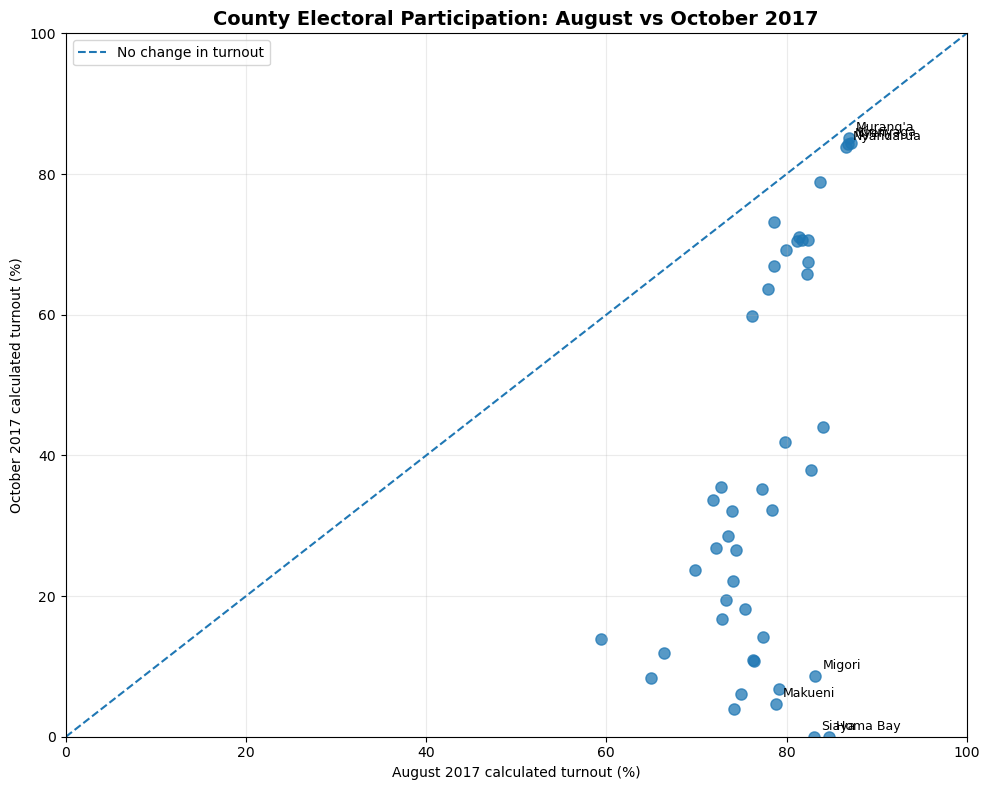

SCATTER PLOT VALIDATION
Counties plotted: 45
Counties below the no-change line: 45
Counties above the no-change line: 0


In [37]:

# Notebook 04 — Cell 8
# Visualise county turnout changes between August and October 2017.
# No files are modified or exported.

import matplotlib.pyplot as plt

plot_df = comparable_counties_2017.copy()

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    plot_df["august_turnout_pct"],
    plot_df["october_turnout_pct"],
    s=65,
    alpha=0.75
)

# Reference line: identical turnout in both elections.
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1.5,
    label="No change in turnout"
)

# Annotate counties at the extremes of turnout change.
counties_to_label = [
    "Homa Bay",
    "Siaya",
    "Migori",
    "Makueni",
    "Murang'a",
    "Nyeri",
    "Nyandarua",
    "Kirinyaga"
]

for _, row in plot_df.iterrows():
    if row["county"] in counties_to_label:
        ax.annotate(
            row["county"],
            (
                row["august_turnout_pct"],
                row["october_turnout_pct"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

ax.set_xlabel("August 2017 calculated turnout (%)")
ax.set_ylabel("October 2017 calculated turnout (%)")

ax.set_title(
    "County Electoral Participation: August vs October 2017",
    fontsize=14,
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("SCATTER PLOT VALIDATION")
print("=" * 65)
print("Counties plotted:", len(plot_df))
print(
    "Counties below the no-change line:",
    (
        plot_df["october_turnout_pct"]
        < plot_df["august_turnout_pct"]
    ).sum()
)
print(
    "Counties above the no-change line:",
    (
        plot_df["october_turnout_pct"]
        > plot_df["august_turnout_pct"]
    ).sum()
)


The chart suggests distinct participation patterns, although we have not yet established whether they represent statistically meaningful clusters.

One useful observation is that most counties had August turnout concentrated around 70–85%, yet their October turnout ranged from almost zero to more than 80%. Similar participation levels in August did not translate into similar participation levels in October.

### Classify turnout declines
To make the county comparisons easier to communicate, let's classify the magnitude of turnout decline using transparent, descriptive thresholds.

These categories are analytical conventions, not statistical clusters or political classifications.

In [41]:

# Notebook 04 — Cell 9
# Classify August-to-October 2017 county turnout declines.
# Descriptive thresholds, not statistical clustering.
# No existing files are modified.

classification_df = comparable_counties_2017.copy()

# Convert negative turnout changes to positive decline magnitudes.
classification_df["decline_magnitude_pp"] = (
    -classification_df["turnout_change_pp"]
)

# Confirm all comparable counties experienced a decline.
assert (
    classification_df["decline_magnitude_pp"] > 0
).all()

# Apply explicit descriptive thresholds.
classification_df["decline_category"] = pd.cut(
    classification_df["decline_magnitude_pp"],
    bins=[0, 15, 40, 65, np.inf],
    labels=[
        "Limited decline",
        "Moderate decline",
        "Large decline",
        "Severe decline"
    ],
    right=False
)

# Add August registered-voter counts for population weighting.
august_registration = elections_df.loc[
    elections_df["election_id"].eq("2017_AUG_GENERAL"),
    ["county_key", "analytical_registered_voters"]
].rename(
    columns={
        "analytical_registered_voters":
        "august_registered_voters"
    }
)

classification_df = classification_df.merge(
    august_registration,
    on="county_key",
    how="left",
    validate="one_to_one"
)

assert classification_df["august_registered_voters"].notna().all()

# Summarise the categories.
category_summary = (
    classification_df
    .groupby("decline_category", observed=False)
    .agg(
        counties=("county", "count"),
        registered_voters=("august_registered_voters", "sum"),
        mean_decline_pp=("decline_magnitude_pp", "mean"),
        median_decline_pp=("decline_magnitude_pp", "median")
    )
    .reset_index()
)

category_summary["county_share_pct"] = (
    category_summary["counties"]
    / len(classification_df)
    * 100
)

category_summary["registered_voter_share_pct"] = (
    category_summary["registered_voters"]
    / classification_df["august_registered_voters"].sum()
    * 100
)

print("2017 TURNOUT DECLINE CLASSIFICATION")
print("=" * 65)

display(category_summary.round(2))

print("\nCOUNTIES BY DECLINE CATEGORY")

for category in classification_df["decline_category"].cat.categories:

    subset = classification_df.loc[
        classification_df["decline_category"].eq(category)
    ].sort_values("decline_magnitude_pp")

    print(f"\n{category.upper()} ({len(subset)} counties)")

    display(
        subset[
            [
                "county",
                "august_turnout_pct",
                "october_turnout_pct",
                "decline_magnitude_pp"
            ]
        ].round(2)
    )

print("\nCLASSIFICATION VALIDATION")
print("Counties classified:", category_summary["counties"].sum())
print(
    "Registered voters represented:",
    category_summary["registered_voters"].sum()
)

assert category_summary["counties"].sum() == 45
assert (
    category_summary["registered_voters"].sum()
    == 18876036
)

print("Validation: PASSED")


2017 TURNOUT DECLINE CLASSIFICATION


,decline_category,counties,registered_voters,mean_decline_pp,median_decline_pp,county_share_pct,registered_voter_share_pct
0,Limited decline,14,6557985,8.25,10.52,31.11,34.74
1,Moderate decline,6,3595700,31.04,37.59,13.33,19.05
2,Large decline,16,4512971,49.88,47.07,35.56,23.91
3,Severe decline,9,4209380,73.22,72.38,20.00,22.3



COUNTIES BY DECLINE CATEGORY

LIMITED DECLINE (14 counties)


,county,august_turnout_pct,october_turnout_pct,decline_magnitude_pp
27,Murang'a,86.88,85.17,1.71
34,Nyeri,86.82,84.23,2.59
33,Nyandarua,86.56,83.81,2.75
14,Kirinyaga,87.15,84.36,2.79
12,Kiambu,83.74,78.81,4.93
11,Kericho,78.64,73.17,5.47
4,Elgeyo-Marakwet,81.35,70.98,10.37
29,Nakuru,79.91,69.24,10.67
18,Laikipia,81.21,70.41,10.80
5,Embu,81.69,70.65,11.04



MODERATE DECLINE (6 counties)


,county,august_turnout_pct,october_turnout_pct,decline_magnitude_pp
41,Uasin Gishu,76.22,59.78,16.44
0,Baringo,82.29,65.85,16.44
28,Nairobi City,72.68,35.49,37.19
9,Kajiado,79.81,41.83,37.98
19,Lamu,71.80,33.60,38.20
44,West Pokot,84.07,44.07,40.00



LARGE DECLINE (16 counties)


,county,august_turnout_pct,october_turnout_pct,decline_magnitude_pp
32,Nyamira,73.97,32.10,41.87
35,Samburu,77.33,35.24,42.09
31,Narok,82.69,37.87,44.82
40,Trans Nzoia,73.51,28.53,44.98
8,Isiolo,72.15,26.87,45.28
26,Mombasa,59.45,13.94,45.51
6,Garissa,69.86,23.75,46.11
23,Marsabit,78.42,32.17,46.25
15,Kisii,74.39,26.50,47.89
38,Tana River,74.05,22.17,51.88



SEVERE DECLINE (9 counties)


,county,august_turnout_pct,october_turnout_pct,decline_magnitude_pp
20,Machakos,76.24,10.93,65.31
16,Kitui,76.36,10.70,65.66
10,Kakamega,74.94,6.01,68.93
42,Vihiga,74.14,3.98,70.16
3,Busia,79.16,6.78,72.38
21,Makueni,78.85,4.64,74.21
25,Migori,83.20,8.64,74.56
36,Siaya,83.02,0.00,83.02
7,Homa Bay,84.71,0.00,84.71



CLASSIFICATION VALIDATION
Counties classified: 45
Registered voters represented: 18876036
Validation: PASSED


**What stands out?**

**Limited decline:** Fourteen counties maintained relatively stable participation. They accounted for 34.74% of registered voters in the comparable dataset. Murang'a, Nyeri, Nyandarua and Kirinyaga had particularly small declines.

**Moderate decline:** Only six counties fall into this category. Interestingly, the group includes Nairobi City, which recorded a decline of 37.19 percentage points.

**Large decline:** Sixteen counties experienced declines between 40 and 65 percentage points. This was the largest category by county count.

**Severe decline:** Nine counties experienced declines of at least 65 percentage points. Their average decline was 73.22 percentage points, and they represented 22.30% of the registered electorate included in the comparison.

***An important distinction:*** these voter shares describe the distribution of registered voters across county categories, not the proportion of voters who abstained or changed their voting behaviour.

### Visualise the decline categories
We should now produce a visual that combines the number of counties in each category with the size of their registered electorate.

This is a useful comparison because a category with relatively few counties can still represent a substantial proportion of registered voters.

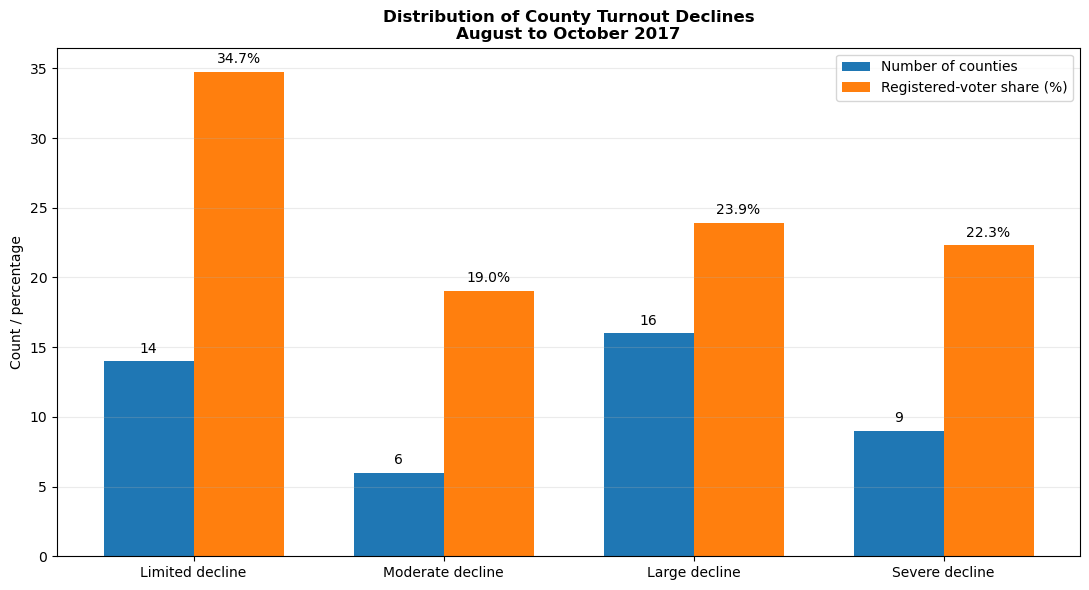

CLASSIFICATION VISUALISATION CHECK
Total counties: 45
Total registered-voter share: 100.0
Validation: PASSED


In [46]:

# Notebook 04 — Cell 10
# Visualise the distribution of 2017 turnout decline categories.
# No existing files are modified.

import matplotlib.pyplot as plt
import numpy as np

plot_summary = category_summary.copy()

categories = plot_summary["decline_category"].astype(str)
county_counts = plot_summary["counties"].astype(int)
voter_shares = plot_summary["registered_voter_share_pct"].astype(float)

x = np.arange(len(categories))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

bars_counties = ax.bar(
    x - bar_width / 2,
    county_counts,
    bar_width,
    label="Number of counties"
)

bars_voters = ax.bar(
    x + bar_width / 2,
    voter_shares,
    bar_width,
    label="Registered-voter share (%)"
)

# Label each bar.
for bar in bars_counties:
    ax.annotate(
        f"{bar.get_height():.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

for bar in bars_voters:
    ax.annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

ax.set_xticks(x)
ax.set_xticklabels(categories)

ax.set_ylabel("Count / percentage")
ax.set_title(
    "Distribution of County Turnout Declines\n"
    "August to October 2017",
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("CLASSIFICATION VISUALISATION CHECK")
print("=" * 65)
print("Total counties:", county_counts.sum())
print("Total registered-voter share:", round(voter_shares.sum(), 2))

assert county_counts.sum() == 45
assert np.isclose(voter_shares.sum(), 100.0)

print("Validation: PASSED")


**The most interesting findings are:**
- Large and severe declines affected 25 counties, representing 55.56% of comparable counties and 46.21% of their registered voters.
- Limited declines affected 14 counties, accounting for a larger share of registered voters (34.74%) than their share of counties (31.11%).
- Moderate declines affected just six counties, but those counties accounted for 19.05% of registered voters.

The results demonstrate why county counts and registered-voter shares should be examined together.

One presentation improvement for our final report: we should separate the two measures into individual charts because county counts and percentages have different units.

### Compare general-election participation by county
We will construct a county-level comparison across the three general elections. Minus the 2017 October election.

To ensure that changes are comparable, the first analysis will include only counties with valid-vote participation figures for all three elections.

This gives us a consistent set of counties for evaluating changes over time.

In [51]:

# Notebook 04 — Cell 11
# Compare valid-vote participation across general elections.
# October 2017 is excluded because it was a fresh election.
# No existing files are modified.

general_election_ids = [
    "2013_GENERAL",
    "2017_AUG_GENERAL",
    "2022_GENERAL"
]

general_elections_df = elections_df.loc[
    elections_df["election_id"].isin(general_election_ids),
    [
        "county",
        "county_key",
        "election_id",
        "valid_vote_participation_pct",
        "analytical_registered_voters",
        "county_validation_status"
    ]
].copy()

# Create one row per county with separate election columns.
general_participation_wide = (
    general_elections_df
    .pivot(
        index=["county_key", "county"],
        columns="election_id",
        values="valid_vote_participation_pct"
    )
    .reset_index()
    .rename(
        columns={
            "2013_GENERAL": "participation_2013_pct",
            "2017_AUG_GENERAL": "participation_2017_pct",
            "2022_GENERAL": "participation_2022_pct"
        }
    )
)

# Calculate percentage-point changes.
general_participation_wide["change_2013_2017_pp"] = (
    general_participation_wide["participation_2017_pct"]
    - general_participation_wide["participation_2013_pct"]
)

general_participation_wide["change_2017_2022_pp"] = (
    general_participation_wide["participation_2022_pct"]
    - general_participation_wide["participation_2017_pct"]
)

general_participation_wide["change_2013_2022_pp"] = (
    general_participation_wide["participation_2022_pct"]
    - general_participation_wide["participation_2013_pct"]
)

# Identify counties with complete data for all three elections.
general_participation_wide["comparison_status"] = np.where(
    general_participation_wide[
        [
            "participation_2013_pct",
            "participation_2017_pct",
            "participation_2022_pct"
        ]
    ].notna().all(axis=1),
    "COMPLETE_THREE_ELECTIONS",
    "INCOMPLETE"
)

general_comparable_df = general_participation_wide.loc[
    general_participation_wide["comparison_status"].eq(
        "COMPLETE_THREE_ELECTIONS"
    )
].copy()

print("GENERAL ELECTION PARTICIPATION COMPARISON")
print("=" * 65)

print("\nCOMPARISON COVERAGE")
print("Total counties:", len(general_participation_wide))
print("Counties with complete data:", len(general_comparable_df))

print("\nCOUNTIES WITH INCOMPLETE DATA")
display(
    general_participation_wide.loc[
        general_participation_wide["comparison_status"].eq(
            "INCOMPLETE"
        ),
        ["county", "comparison_status"]
    ]
)

print("\nPARTICIPATION CHANGE SUMMARY")

change_columns = [
    "change_2013_2017_pp",
    "change_2017_2022_pp",
    "change_2013_2022_pp"
]

display(
    general_comparable_df[
        change_columns
    ].agg(["mean", "median", "min", "max", "std"]).round(2)
)

print("\nTEN LARGEST DECLINES: 2013 TO 2022")

display(
    general_comparable_df
    .sort_values("change_2013_2022_pp")
    .head(10)[
        [
            "county",
            "participation_2013_pct",
            "participation_2022_pct",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

print("\nTEN SMALLEST DECLINES OR LARGEST INCREASES: 2013 TO 2022")

display(
    general_comparable_df
    .sort_values("change_2013_2022_pp", ascending=False)
    .head(10)[
        [
            "county",
            "participation_2013_pct",
            "participation_2022_pct",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

print("\nDIRECTION OF CHANGE: 2013 TO 2022")

direction_summary = pd.Series({
    "Declining participation": (
        general_comparable_df["change_2013_2022_pp"] < 0
    ).sum(),
    "Increasing participation": (
        general_comparable_df["change_2013_2022_pp"] > 0
    ).sum(),
    "Unchanged participation": (
        general_comparable_df["change_2013_2022_pp"] == 0
    ).sum()
})

display(direction_summary.to_frame(name="count"))

# Validate expected coverage.
assert len(general_participation_wide) == 47
assert len(general_comparable_df) == 45

print("\nValidation: PASSED")


GENERAL ELECTION PARTICIPATION COMPARISON

COMPARISON COVERAGE
Total counties: 47
Counties with complete data: 45

COUNTIES WITH INCOMPLETE DATA


election_id,county,comparison_status
16,Kisumu,INCOMPLETE
42,Turkana,INCOMPLETE



PARTICIPATION CHANGE SUMMARY


election_id,change_2013_2017_pp,change_2017_2022_pp,change_2013_2022_pp
mean,-7.86,-11.49,-19.36
median,-7.94,-12.11,-20.54
min,-14.95,-19.63,-26.19
max,0.33,-0.18,-9.72
std,2.46,4.97,4.41



TEN LARGEST DECLINES: 2013 TO 2022


election_id,county,participation_2013_pct,participation_2022_pct,change_2013_2022_pp
34,Nyandarua,92.80,66.61,-26.19
19,Laikipia,89.63,64.22,-25.41
29,Nairobi City,80.73,55.42,-25.31
12,Kiambu,89.98,64.71,-25.27
28,Murang'a,92.85,67.69,-25.16
6,Garissa,79.30,54.57,-24.73
35,Nyeri,92.02,67.82,-24.20
22,Makueni,83.78,60.65,-23.13
21,Machakos,82.45,59.65,-22.80
10,Kakamega,82.33,59.63,-22.70



TEN SMALLEST DECLINES OR LARGEST INCREASES: 2013 TO 2022


election_id,county,participation_2013_pct,participation_2022_pct,change_2013_2022_pp
1,Bomet,89.19,79.47,-9.72
46,West Pokot,89.16,78.94,-10.22
11,Kericho,89.70,78.13,-11.57
32,Narok,88.95,77.33,-11.62
0,Baringo,89.79,77.23,-12.56
31,Nandi,88.27,75.68,-12.59
4,Elgeyo-Marakwet,90.38,77.24,-13.14
39,Tana River,80.46,66.26,-14.20
13,Kilifi,64.15,48.48,-15.67
43,Uasin Gishu,84.85,69.10,-15.75



DIRECTION OF CHANGE: 2013 TO 2022


,count
Declining participation,45
Increasing participation,0
Unchanged participation,0



Validation: PASSED


Valid-vote participation declined between 2013 and 2022 in every one of the 45 counties with complete three-election data.

This is potentially one of the central findings of the Kenya Electoral Participation Analytics project.

The results suggest that the decline in valid-vote participation was larger between 2017 and 2022 than between 2013 and 2017.

Unlike the August–October 2017 comparison, which revealed exceptionally uneven changes, the 2013–2022 decline appears more widespread and comparatively consistent across counties.

However, the 2022 county data remains independently unverified, so these findings should be described as patterns in the reconciled analytical dataset, rather than definitive official county-level trends.

***An especially interesting contrast is emerging:*** some counties that maintained high participation during the October 2017 fresh election nevertheless experienced substantial declines between the 2013 and 2022 general elections.

Murang'a, Nyeri and Nyandarua are examples.

This suggests that short-term participation stability during the fresh election and longer-term general-election participation trends are different phenomena.

### Visualise general-election participation trends
Let's now compare the three general elections using a line chart that displays the mean and median valid-vote participation across the same 45 counties.

We will deliberately use the consistent 45-county sample so changes in the displayed figures are not caused by different counties entering or leaving the analysis.

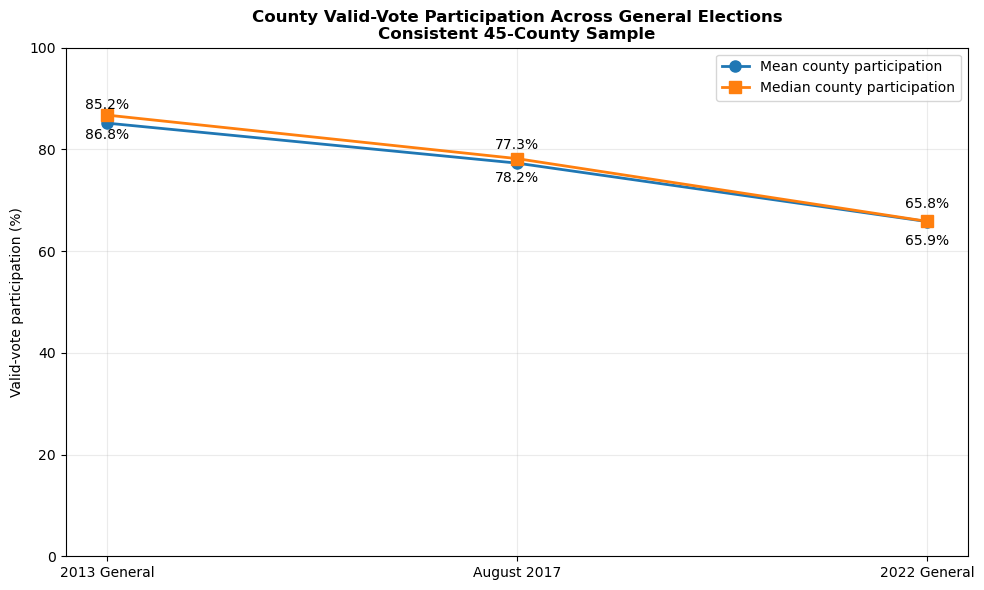

GENERAL ELECTION PARTICIPATION TREND


,election,mean_participation,median_participation
0,2013 General,85.18,86.76
1,August 2017,77.31,78.20
2,2022 General,65.82,65.87



Coverage: 45 counties
Validation: PASSED


In [57]:

# Notebook 04 — Cell 12
# Visualise valid-vote participation across general elections.
# Consistent sample: 45 counties with complete data.
# No files are modified.

import matplotlib.pyplot as plt

participation_trend = pd.DataFrame({
    "election": ["2013 General", "August 2017", "2022 General"],
    "mean_participation": [
        general_comparable_df["participation_2013_pct"].mean(),
        general_comparable_df["participation_2017_pct"].mean(),
        general_comparable_df["participation_2022_pct"].mean()
    ],
    "median_participation": [
        general_comparable_df["participation_2013_pct"].median(),
        general_comparable_df["participation_2017_pct"].median(),
        general_comparable_df["participation_2022_pct"].median()
    ]
})

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    participation_trend["election"],
    participation_trend["mean_participation"],
    marker="o",
    linewidth=2,
    markersize=8,
    label="Mean county participation"
)

ax.plot(
    participation_trend["election"],
    participation_trend["median_participation"],
    marker="s",
    linewidth=2,
    markersize=8,
    label="Median county participation"
)

# Label the plotted values.
for _, row in participation_trend.iterrows():
    ax.annotate(
        f"{row['mean_participation']:.1f}%",
        (row["election"], row["mean_participation"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

    ax.annotate(
        f"{row['median_participation']:.1f}%",
        (row["election"], row["median_participation"]),
        xytext=(0, -17),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylim(0, 100)
ax.set_ylabel("Valid-vote participation (%)")

ax.set_title(
    "County Valid-Vote Participation Across General Elections\n"
    "Consistent 45-County Sample",
    fontweight="bold"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("GENERAL ELECTION PARTICIPATION TREND")
print("=" * 65)

display(participation_trend.round(2))

print("\nCoverage:", len(general_comparable_df), "counties")

assert len(general_comparable_df) == 45

print("Validation: PASSED")


The average county valid-vote participation rate declined by approximately 19.36 percentage points between 2013 and 2022.

The decline was larger between 2017 and 2022 (11.49 pp) than between 2013 and 2017 (7.86 pp). However, because those intervals span different numbers of years, this does not by itself establish that the annual rate of decline accelerated.

The median follows the same downward pattern as the mean. By 2022, the two figures were almost identical, suggesting that the distribution of county participation became more balanced around its centre. We would need to examine the full distribution to establish whether variation between counties also narrowed.

**An emerging project narrative**

Our analysis is developing around three findings.

Registration expanded: Kenya's registered electorate grew by approximately 53.7% between 2013 and 2022 in our county dataset.

General-election participation declined: All 45 counties in our consistent comparison recorded lower valid-vote participation in 2022 than in 2013.

Participation changes were not uniform: The October 2017 fresh election demonstrated especially large differences in participation between counties.

Together, these findings raise an important question: Has the growth in Kenya's registered electorate been accompanied by a weakening of participation rates, and how differently has this developed across counties?

We can investigate this descriptively without assuming the reasons for the changes.

### Identify consistently high- and low-participation counties

Our next step is to examine county rankings across the three general elections.

Rather than focusing only on absolute participation declines, we want to understand whether counties maintained their relative positions.

For example, a county could experience a substantial decline in participation while remaining among the highest-participation counties nationally.

The following cell will calculate each county's participation ranking in 2013, August 2017 and 2022, then examine how those rankings changed.

In [62]:

# Notebook 04 — Cell 13
# Examine county participation rankings across general elections.
# Consistent 45-county sample; no files are modified.

county_rankings = general_comparable_df[
    [
        "county",
        "county_key",
        "participation_2013_pct",
        "participation_2017_pct",
        "participation_2022_pct"
    ]
].copy()

# Rank counties from highest to lowest participation.
# Rank 1 = highest participation.
county_rankings["rank_2013"] = (
    county_rankings["participation_2013_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

county_rankings["rank_2017"] = (
    county_rankings["participation_2017_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

county_rankings["rank_2022"] = (
    county_rankings["participation_2022_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive values indicate a movement down the ranking.
county_rankings["rank_change_2013_2022"] = (
    county_rankings["rank_2022"]
    - county_rankings["rank_2013"]
)

# Average participation across the three general elections.
# This is descriptive and gives each election equal weight.
county_rankings["average_participation_pct"] = (
    county_rankings[
        [
            "participation_2013_pct",
            "participation_2017_pct",
            "participation_2022_pct"
        ]
    ].mean(axis=1)
)

print("COUNTY PARTICIPATION RANKINGS")
print("=" * 65)

print("\nTEN HIGHEST AVERAGE PARTICIPATION COUNTIES")

display(
    county_rankings
    .sort_values("average_participation_pct", ascending=False)
    .head(10)[
        [
            "county",
            "average_participation_pct",
            "rank_2013",
            "rank_2017",
            "rank_2022"
        ]
    ].round(2)
)

print("\nTEN LOWEST AVERAGE PARTICIPATION COUNTIES")

display(
    county_rankings
    .sort_values("average_participation_pct")
    .head(10)[
        [
            "county",
            "average_participation_pct",
            "rank_2013",
            "rank_2017",
            "rank_2022"
        ]
    ].round(2)
)

print("\nLARGEST IMPROVEMENTS IN RELATIVE RANKING")

display(
    county_rankings
    .sort_values("rank_change_2013_2022")
    .head(10)[
        [
            "county",
            "rank_2013",
            "rank_2022",
            "rank_change_2013_2022"
        ]
    ]
)

print("\nLARGEST DECLINES IN RELATIVE RANKING")

display(
    county_rankings
    .sort_values("rank_change_2013_2022", ascending=False)
    .head(10)[
        [
            "county",
            "rank_2013",
            "rank_2022",
            "rank_change_2013_2022"
        ]
    ]
)

print("\nRANKING CONSISTENCY")

rank_correlation = county_rankings[
    ["rank_2013", "rank_2017", "rank_2022"]
].corr(method="spearman")

display(rank_correlation.round(3))

assert len(county_rankings) == 45
print("\nValidation: PASSED")


COUNTY PARTICIPATION RANKINGS

TEN HIGHEST AVERAGE PARTICIPATION COUNTIES


election_id,county,average_participation_pct,rank_2013,rank_2017,rank_2022
46,West Pokot,83.97,14,6,2
7,Homa Bay,83.82,1,5,9
1,Bomet,83.52,13,12,1
0,Baringo,82.99,10,11,6
32,Narok,82.93,15,10,4
4,Elgeyo-Marakwet,82.90,7,15,5
26,Migori,82.85,6,8,8
28,Murang'a,82.41,2,1,17
35,Nyeri,82.15,4,2,16
11,Kericho,82.05,11,21,3



TEN LOWEST AVERAGE PARTICIPATION COUNTIES


election_id,county,average_participation_pct,rank_2013,rank_2017,rank_2022
27,Mombasa,55.78,44,45,45
13,Kilifi,59.04,45,44,44
18,Kwale,63.79,43,43,43
6,Garissa,67.73,42,42,42
29,Nairobi City,69.51,38,38,41
38,Taita Taveta,71.18,40,39,36
44,Vihiga,71.53,37,33,40
20,Lamu,71.71,33,41,35
41,Trans Nzoia,71.78,41,36,31
10,Kakamega,72.12,36,31,39



LARGEST IMPROVEMENTS IN RELATIVE RANKING


election_id,county,rank_2013,rank_2022,rank_change_2013_2022
39,Tana River,39,21,-18
46,West Pokot,14,2,-12
1,Bomet,13,1,-12
43,Uasin Gishu,26,14,-12
32,Narok,15,4,-11
41,Trans Nzoia,41,31,-10
31,Nandi,17,7,-10
24,Marsabit,25,15,-10
11,Kericho,11,3,-8
36,Samburu,18,11,-7



LARGEST DECLINES IN RELATIVE RANKING


election_id,county,rank_2013,rank_2022,rank_change_2013_2022
12,Kiambu,9,26,17
19,Laikipia,12,28,16
28,Murang'a,2,17,15
34,Nyandarua,3,18,15
35,Nyeri,4,16,12
7,Homa Bay,1,9,8
22,Makueni,30,37,7
30,Nakuru,19,25,6
17,Kitui,28,34,6
37,Siaya,5,10,5



RANKING CONSISTENCY


election_id,rank_2013,rank_2017,rank_2022
election_id,,,
rank_2013,1.000,0.917,0.811
rank_2017,0.917,1.000,0.736
rank_2022,0.811,0.736,1.000



Validation: PASSED


The ranking analysis reveals an important distinction: although valid-vote participation declined across all 45 comparable counties between 2013 and 2022, counties did not decline at the same rate, and their relative positions changed.

These results suggest that counties with relatively high participation in one general election generally tended to remain relatively high in subsequent elections.

However, the weaker correlation between August 2017 and 2022 indicates that county rankings shifted more substantially during that comparison.

The correlation measures similarity in rankings, not whether participation rates increased or decreased.

Tana River recorded the largest improvement, moving from 39th position in 2013 to 21st in 2022.

Bomet moved from 13th to 1st, while West Pokot moved from 14th to 2nd.

These counties still experienced lower participation in 2022 than in 2013. Their rankings improved because their declines were generally smaller than those of other counties.

### Examine how county participation rankings changed
Let's **visualise** these movements using a slope chart comparing 2013 and 2022.

Rather than displaying all 45 counties at once, which would make the chart difficult to read, we'll focus on the five largest improvements and five largest declines in relative ranking.

This will make the differences much easier to communicate.

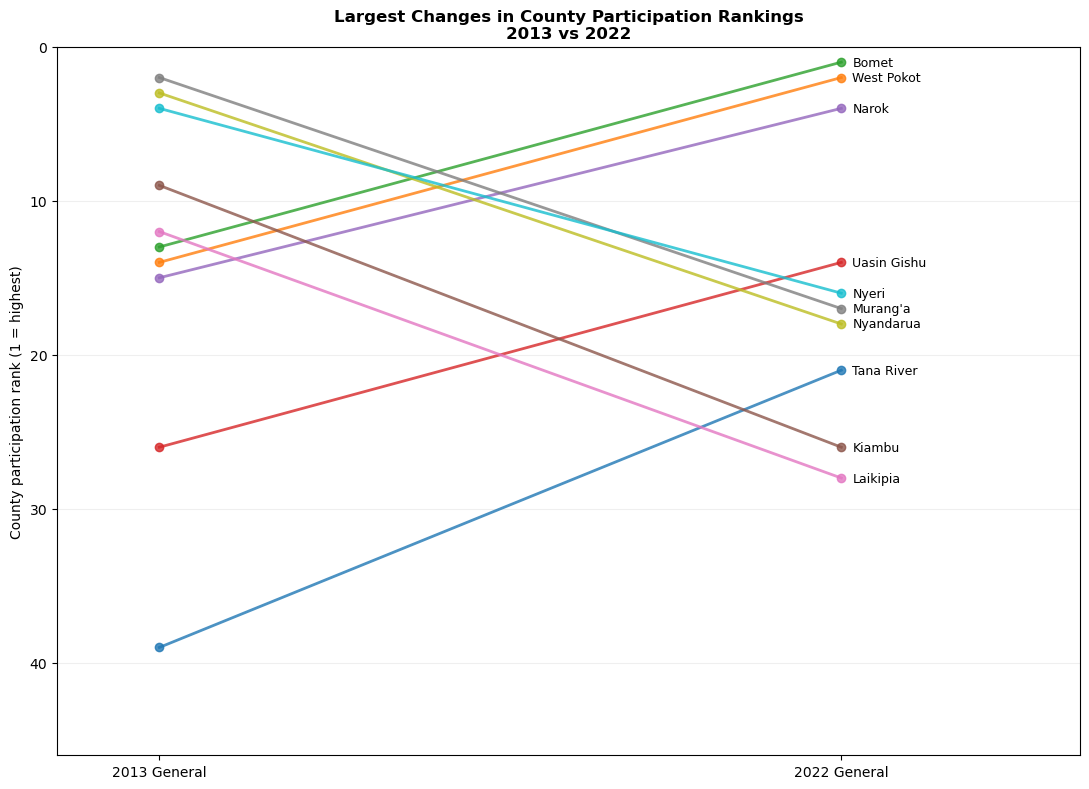

RANKING CHANGE VISUALISATION


election_id,county,rank_2013,rank_2022,rank_change_2013_2022
0,Tana River,39,21,-18
1,West Pokot,14,2,-12
2,Bomet,13,1,-12
3,Uasin Gishu,26,14,-12
4,Narok,15,4,-11
9,Nyeri,4,16,12
7,Murang'a,2,17,15
8,Nyandarua,3,18,15
6,Laikipia,12,28,16
5,Kiambu,9,26,17



Counties displayed: 10
Validation: PASSED


In [68]:

# Notebook 04 — Cell 14
# Visualise major county ranking changes, 2013 vs 2022.
# Rankings are based on valid-vote participation.
# Read-only analysis; no files are modified.

import matplotlib.pyplot as plt

# Select five largest improvements and five largest declines.
ranking_improvements = (
    county_rankings
    .sort_values("rank_change_2013_2022")
    .head(5)
)

ranking_declines = (
    county_rankings
    .sort_values("rank_change_2013_2022", ascending=False)
    .head(5)
)

ranking_plot_df = (
    pd.concat(
        [ranking_improvements, ranking_declines],
        ignore_index=True
    )
    .drop_duplicates(subset="county_key")
)

fig, ax = plt.subplots(figsize=(11, 8))

for _, row in ranking_plot_df.iterrows():

    rank_2013 = row["rank_2013"]
    rank_2022 = row["rank_2022"]

    ax.plot(
        [0, 1],
        [rank_2013, rank_2022],
        marker="o",
        linewidth=2,
        alpha=0.8
    )

    # Label each county at the 2022 endpoint.
    ax.annotate(
        row["county"],
        (1, rank_2022),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xticks([0, 1])
ax.set_xticklabels(["2013 General", "2022 General"])

# Rank 1 is the highest participation rank.
ax.invert_yaxis()

ax.set_ylim(46, 0)
ax.set_xlim(-0.15, 1.35)

ax.set_ylabel("County participation rank (1 = highest)")

ax.set_title(
    "Largest Changes in County Participation Rankings\n"
    "2013 vs 2022",
    fontweight="bold"
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("RANKING CHANGE VISUALISATION")
print("=" * 65)

display(
    ranking_plot_df[
        [
            "county",
            "rank_2013",
            "rank_2022",
            "rank_change_2013_2022"
        ]
    ].sort_values("rank_change_2013_2022")
)

print("\nCounties displayed:", len(ranking_plot_df))

assert len(ranking_plot_df) == 10

print("Validation: PASSED")


The results reinforce an important finding: although valid-vote participation declined across all 45 comparable counties, some counties improved their relative position because their participation declined less than elsewhere.

### Registration growth versus participation change
We will compare county-level registration growth between 2013 and 2022 against changes in valid-vote participation over the same period.

To preserve consistency with our previous analysis, we will initially use the same 45 counties.

The cell will calculate registration growth in both absolute and percentage terms, then assess its association with participation change using Pearson and Spearman correlations.

In [72]:

# Notebook 04 — Cell 15
# Examine registration growth versus participation change.
# Consistent 45-county sample, 2013 to 2022.
# No source files or existing datasets are modified.

# Select registration counts for 2013 and 2022.
registration_2013_2022 = elections_df.loc[
    elections_df["election_id"].isin([
        "2013_GENERAL",
        "2022_GENERAL"
    ]),
    [
        "county_key",
        "county",
        "election_id",
        "analytical_registered_voters"
    ]
].copy()

# Reshape registration counts into separate year columns.
registration_wide = (
    registration_2013_2022
    .pivot(
        index=["county_key", "county"],
        columns="election_id",
        values="analytical_registered_voters"
    )
    .reset_index()
    .rename(
        columns={
            "2013_GENERAL": "registered_2013",
            "2022_GENERAL": "registered_2022"
        }
    )
)

# Merge with the existing 45-county participation comparison.
registration_participation_df = general_comparable_df[
    [
        "county_key",
        "county",
        "participation_2013_pct",
        "participation_2022_pct",
        "change_2013_2022_pp"
    ]
].merge(
    registration_wide[
        [
            "county_key",
            "registered_2013",
            "registered_2022"
        ]
    ],
    on="county_key",
    how="left",
    validate="one_to_one"
)

# Calculate registration growth.
registration_participation_df["registration_growth_absolute"] = (
    registration_participation_df["registered_2022"]
    - registration_participation_df["registered_2013"]
)

registration_participation_df["registration_growth_pct"] = (
    registration_participation_df["registration_growth_absolute"]
    / registration_participation_df["registered_2013"]
    * 100
)

# Validate the inputs.
assert len(registration_participation_df) == 45

assert registration_participation_df[
    ["registered_2013", "registered_2022"]
].notna().all().all()

assert (
    registration_participation_df["registered_2013"] > 0
).all()

print("REGISTRATION GROWTH VS PARTICIPATION CHANGE")
print("=" * 65)

print("\nREGISTRATION GROWTH SUMMARY")

display(
    registration_participation_df[
        [
            "registration_growth_absolute",
            "registration_growth_pct",
            "change_2013_2022_pp"
        ]
    ].agg(["mean", "median", "min", "max", "std"]).round(2)
)

print("\nTEN COUNTIES WITH HIGHEST REGISTRATION GROWTH (%)")

display(
    registration_participation_df
    .sort_values("registration_growth_pct", ascending=False)
    .head(10)[
        [
            "county",
            "registered_2013",
            "registered_2022",
            "registration_growth_pct",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

print("\nTEN COUNTIES WITH LOWEST REGISTRATION GROWTH (%)")

display(
    registration_participation_df
    .sort_values("registration_growth_pct")
    .head(10)[
        [
            "county",
            "registered_2013",
            "registered_2022",
            "registration_growth_pct",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

# Calculate correlation coefficients.
correlation_columns = [
    "registration_growth_pct",
    "change_2013_2022_pp"
]

pearson_correlation = (
    registration_participation_df[correlation_columns]
    .corr(method="pearson")
    .iloc[0, 1]
)

spearman_correlation = (
    registration_participation_df[correlation_columns]
    .corr(method="spearman")
    .iloc[0, 1]
)

print("\nCORRELATION ANALYSIS")

print(f"Pearson correlation:  {pearson_correlation:.3f}")
print(f"Spearman correlation: {spearman_correlation:.3f}")

print("\nVALIDATION")
print("Counties analysed:", len(registration_participation_df))
print("Validation: PASSED")


REGISTRATION GROWTH VS PARTICIPATION CHANGE

REGISTRATION GROWTH SUMMARY


election_id,registration_growth_absolute,registration_growth_pct,change_2013_2022_pp
mean,164418.96,57.81,-19.36
median,137179.00,55.60,-20.54
min,29109.00,34.99,-26.19
max,684263.00,87.00,-9.72
std,114858.07,12.20,4.41



TEN COUNTIES WITH HIGHEST REGISTRATION GROWTH (%)


election_id,county,registered_2013,registered_2022,registration_growth_pct,change_2013_2022_pp
17,Kwale,175572,328316,87.0,-16.46
44,West Pokot,121204,220042,81.55,-10.22
22,Mandera,120923,217034,79.48,-21.29
38,Tana River,79641,141110,77.18,-14.20
43,Wajir,118245,207767,75.71,-20.11
13,Kilifi,336410,588842,75.04,-15.67
6,Garissa,115236,201513,74.87,-24.73
36,Siaya,312441,533602,70.78,-21.24
7,Homa Bay,326505,551111,68.79,-20.29
3,Busia,251517,416818,65.72,-20.54



TEN COUNTIES WITH LOWEST REGISTRATION GROWTH (%)


election_id,county,registered_2013,registered_2022,registration_growth_pct,change_2013_2022_pp
34,Nyeri,357059,482000,34.99,-24.20
27,Murang'a,453725,621027,36.87,-25.16
28,Nairobi City,1732288,2416551,39.5,-25.31
33,Nyandarua,256425,361217,40.87,-26.19
14,Kirinyaga,265567,376137,41.64,-20.97
5,Embu,227638,334684,47.02,-20.89
11,Kericho,290947,428126,47.15,-11.57
32,Nyamira,219428,323283,47.33,-18.05
12,Kiambu,863199,1275168,47.73,-25.27
10,Kakamega,568151,844709,48.68,-22.70



CORRELATION ANALYSIS
Pearson correlation:  0.297
Spearman correlation: 0.319

VALIDATION
Counties analysed: 45
Validation: PASSED


The central finding is that counties with faster registration growth tended to experience smaller declines in valid-vote participation between 2013 and 2022, although the relationship is relatively weak.

Both coefficients are positive because we measured participation change as the 2022 rate minus the 2013 rate. Since all 45 counties recorded negative changes, a higher value means a smaller decline.

Three findings are emerging:
- Registration expanded across the comparable counties. Average county registration growth was 57.81%.
- Participation rates declined in every comparable county. The average decline was 19.36 percentage points.
- Faster registration growth was modestly associated with smaller participation declines. The correlation coefficients were approximately +0.30.


To understand this relationship more fully, we should also examine how the absolute number of valid votes changed. A declining participation rate does not necessarily mean fewer people cast valid votes.

### Registration growth versus valid-vote growth
This is an important extension of our analysis.

So far, we have focused primarily on participation percentages. However, a county can experience an increase in the absolute number of valid votes while its participation rate declines because its registered electorate grew faster.

We will now compare the growth in registered voters against the growth in valid votes between 2013 and 2022.

In [77]:

# Notebook 04 — Cell 16
# Compare registration growth with valid-vote growth, 2013–2022.
# Consistent 45-county sample.
# No existing files are modified.

# Extract valid-vote counts for the two general elections.
valid_votes_source = elections_df.loc[
    elections_df["election_id"].isin([
        "2013_GENERAL",
        "2022_GENERAL"
    ]),
    [
        "county_key",
        "election_id",
        "analytical_valid_votes"
    ]
].copy()

# Reshape into separate election columns.
valid_votes_wide = (
    valid_votes_source
    .pivot(
        index="county_key",
        columns="election_id",
        values="analytical_valid_votes"
    )
    .reset_index()
    .rename(
        columns={
            "2013_GENERAL": "valid_votes_2013",
            "2022_GENERAL": "valid_votes_2022"
        }
    )
)

# Combine with the registration-growth dataset.
vote_growth_df = registration_participation_df.merge(
    valid_votes_wide,
    on="county_key",
    how="left",
    validate="one_to_one"
)

# Validate the underlying vote counts.
assert len(vote_growth_df) == 45

assert vote_growth_df[
    ["valid_votes_2013", "valid_votes_2022"]
].notna().all().all()

assert (vote_growth_df["valid_votes_2013"] > 0).all()

# Calculate absolute and percentage changes in valid votes.
vote_growth_df["valid_vote_change_absolute"] = (
    vote_growth_df["valid_votes_2022"]
    - vote_growth_df["valid_votes_2013"]
)

vote_growth_df["valid_vote_growth_pct"] = (
    vote_growth_df["valid_vote_change_absolute"]
    / vote_growth_df["valid_votes_2013"]
    * 100
)

# Compare registration growth with valid-vote growth.
vote_growth_df["growth_gap_pp"] = (
    vote_growth_df["registration_growth_pct"]
    - vote_growth_df["valid_vote_growth_pct"]
)

print("REGISTRATION GROWTH VS VALID-VOTE GROWTH")
print("=" * 65)

print("\nGROWTH SUMMARY")

display(
    vote_growth_df[
        [
            "registration_growth_pct",
            "valid_vote_growth_pct",
            "growth_gap_pp"
        ]
    ].agg(["mean", "median", "min", "max", "std"]).round(2)
)

print("\nDIRECTION OF VALID-VOTE CHANGE")

direction_summary = pd.Series({
    "Counties with more valid votes in 2022": (
        vote_growth_df["valid_vote_change_absolute"] > 0
    ).sum(),
    "Counties with fewer valid votes in 2022": (
        vote_growth_df["valid_vote_change_absolute"] < 0
    ).sum(),
    "Counties with unchanged valid votes": (
        vote_growth_df["valid_vote_change_absolute"] == 0
    ).sum()
})

display(direction_summary.to_frame(name="count"))

print("\nTEN LARGEST GAPS BETWEEN REGISTRATION AND VOTE GROWTH")

display(
    vote_growth_df
    .sort_values("growth_gap_pp", ascending=False)
    .head(10)[
        [
            "county",
            "registration_growth_pct",
            "valid_vote_growth_pct",
            "growth_gap_pp",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

print("\nTEN SMALLEST GAPS")

display(
    vote_growth_df
    .sort_values("growth_gap_pp")
    .head(10)[
        [
            "county",
            "registration_growth_pct",
            "valid_vote_growth_pct",
            "growth_gap_pp",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

# Overall totals for the same 45 counties.
total_registered_2013 = vote_growth_df["registered_2013"].sum()
total_registered_2022 = vote_growth_df["registered_2022"].sum()

total_valid_2013 = vote_growth_df["valid_votes_2013"].sum()
total_valid_2022 = vote_growth_df["valid_votes_2022"].sum()

aggregate_summary = pd.DataFrame({
    "measure": ["Registered voters", "Valid votes"],
    "2013": [total_registered_2013, total_valid_2013],
    "2022": [total_registered_2022, total_valid_2022]
})

aggregate_summary["growth_pct"] = (
    (aggregate_summary["2022"] / aggregate_summary["2013"] - 1)
    * 100
)

print("\nAGGREGATE GROWTH — CONSISTENT 45 COUNTIES")
display(aggregate_summary.round(2))

print("\nVALIDATION")
print("Counties analysed:", len(vote_growth_df))

assert len(vote_growth_df) == 45
assert direction_summary.sum() == 45

print("Validation: PASSED")


REGISTRATION GROWTH VS VALID-VOTE GROWTH

GROWTH SUMMARY


election_id,registration_growth_pct,valid_vote_growth_pct,growth_gap_pp
mean,57.81,21.83,35.99
median,55.60,20.33,37.42
min,34.99,-4.23,16.25
max,87.00,60.75,54.54
std,12.20,13.64,8.58



DIRECTION OF VALID-VOTE CHANGE


,count
Counties with more valid votes in 2022,42
Counties with fewer valid votes in 2022,3
Counties with unchanged valid votes,0



TEN LARGEST GAPS BETWEEN REGISTRATION AND VOTE GROWTH


election_id,county,registration_growth_pct,valid_vote_growth_pct,growth_gap_pp,change_2013_2022_pp
6,Garissa,74.87,20.33,54.54,-24.73
26,Mombasa,55.51,2.97,52.54,-22.03
22,Mandera,79.48,33.86,45.62,-21.29
21,Makueni,60.66,16.31,44.35,-23.13
28,Nairobi City,39.5,-4.23,43.73,-25.31
16,Kitui,64.05,20.33,43.72,-22.44
17,Kwale,87.0,43.64,43.36,-16.46
18,Laikipia,51.19,8.34,42.85,-25.41
13,Kilifi,75.04,32.3,42.74,-15.67
20,Machakos,54.39,11.71,42.68,-22.80



TEN SMALLEST GAPS


election_id,county,registration_growth_pct,valid_vote_growth_pct,growth_gap_pp,change_2013_2022_pp
1,Bomet,48.99,32.74,16.25,-9.72
11,Kericho,47.15,28.18,18.97,-11.57
31,Narok,51.44,31.66,19.78,-11.62
44,West Pokot,81.55,60.75,20.8,-10.22
30,Nandi,53.29,31.44,21.85,-12.59
0,Baringo,61.43,38.85,22.58,-12.56
4,Elgeyo-Marakwet,57.88,34.93,22.95,-13.14
41,Uasin Gishu,52.42,24.13,28.3,-15.75
23,Marsabit,58.6,28.3,30.31,-16.26
38,Tana River,77.18,45.92,31.26,-14.20



AGGREGATE GROWTH — CONSISTENT 45 COUNTIES


,measure,2013,2022,growth_pct
0,Registered voters,13865112,21263965,53.36
1,Valid votes,11770740,13632612,15.82



VALIDATION
Counties analysed: 45
Validation: PASSED


**1. The central finding: Registration outpaced valid-vote growth**

The registered electorate grew by approximately 7.40 million, while the number of valid votes increased by approximately 1.86 million.

This means the valid-vote participation rate declined even though the absolute number of valid votes increased.

That distinction is essential for interpreting electoral engagement accurately.

**2. Most counties recorded more valid votes, despite declining participation rates**

This gives us an important distinction:
- All 45 comparable counties experienced declining valid-vote participation rates.
- Yet 42 counties recorded an increase in the absolute number of valid votes.
- Only three counties recorded fewer valid votes in 2022 than in 2013.
Therefore, the decline in participation rates primarily reflects the fact that registered-voter growth exceeded valid-vote growth across the comparable counties, rather than a universal decline in absolute voting volumes.

We should still avoid interpreting valid-vote counts as a complete measure of voting activity, since they exclude rejected ballots.

**3. An important analytical distinction**
We now have two related but different findings.

**Finding A:** Participation rates declined.

Across the 45 comparable counties, average valid-vote participation declined by 19.36 percentage points between 2013 and 2022.

**Finding B:** Absolute valid-vote counts generally increased.

Across the same counties, total valid votes increased by 15.82%.

These findings are not contradictory. They demonstrate why participation rates and absolute vote counts should be analysed together.

### Identify counties with declining absolute valid votes
Before proceeding to visualisations, I recommend investigating the three counties where valid-vote counts actually declined.

These counties may reveal a different participation pattern from the majority.

We should identify them, quantify the changes and compare their registration growth.

In [84]:

# Notebook 04 — Cell 17
# Investigate counties where absolute valid votes declined.
# Consistent 45-county sample, 2013–2022.
# No source files or datasets are modified.

declining_vote_counties = vote_growth_df.loc[
    vote_growth_df["valid_vote_change_absolute"] < 0
].copy()

declining_vote_counties = declining_vote_counties.sort_values(
    "valid_vote_growth_pct"
)

print("COUNTIES WITH DECLINING ABSOLUTE VALID VOTES")
print("=" * 65)

display(
    declining_vote_counties[
        [
            "county",
            "registered_2013",
            "registered_2022",
            "registration_growth_pct",
            "valid_votes_2013",
            "valid_votes_2022",
            "valid_vote_change_absolute",
            "valid_vote_growth_pct",
            "change_2013_2022_pp"
        ]
    ].round(2)
)

print("\nCOUNTIES WITH THE LARGEST ABSOLUTE VALID-VOTE INCREASES")

display(
    vote_growth_df
    .sort_values("valid_vote_change_absolute", ascending=False)
    .head(10)[
        [
            "county",
            "valid_votes_2013",
            "valid_votes_2022",
            "valid_vote_change_absolute",
            "valid_vote_growth_pct",
            "registration_growth_pct"
        ]
    ].round(2)
)

print("\nCOUNTIES WITH THE HIGHEST VALID-VOTE GROWTH (%)")

display(
    vote_growth_df
    .sort_values("valid_vote_growth_pct", ascending=False)
    .head(10)[
        [
            "county",
            "valid_votes_2013",
            "valid_votes_2022",
            "valid_vote_growth_pct",
            "registration_growth_pct"
        ]
    ].round(2)
)

print("\nVALIDATION")

assert len(declining_vote_counties) == 3

assert (
    declining_vote_counties["valid_vote_change_absolute"] < 0
).all()

print("Counties with declining valid votes:", len(declining_vote_counties))
print("Validation: PASSED")


COUNTIES WITH DECLINING ABSOLUTE VALID VOTES


election_id,county,registered_2013,registered_2022,registration_growth_pct,valid_votes_2013,valid_votes_2022,valid_vote_change_absolute,valid_vote_growth_pct,change_2013_2022_pp
28,Nairobi City,1732288,2416551,39.5,1398476,1339367,-59109,-4.23,-25.31
34,Nyeri,357059,482000,34.99,328559,326880,-1679,-0.51,-24.20
27,Murang'a,453725,621027,36.87,421283,420343,-940,-0.22,-25.16



COUNTIES WITH THE LARGEST ABSOLUTE VALID-VOTE INCREASES


election_id,county,valid_votes_2013,valid_votes_2022,valid_vote_change_absolute,valid_vote_growth_pct,registration_growth_pct
7,Homa Bay,305666,404112,98446,32.21,68.79
36,Siaya,286712,376354,89642,31.27,70.78
25,Migori,259892,347773,87881,33.81,65.16
24,Meru,425394,506476,81082,19.06,57.8
29,Nakuru,610803,686170,75367,12.34,51.53
31,Narok,234258,308432,74174,31.66,51.44
1,Bomet,225713,299606,73893,32.74,48.99
30,Nandi,234008,307575,73567,31.44,53.29
11,Kericho,260973,334516,73543,28.18,47.15
13,Kilifi,215792,285496,69704,32.3,75.04



COUNTIES WITH THE HIGHEST VALID-VOTE GROWTH (%)


election_id,county,valid_votes_2013,valid_votes_2022,valid_vote_growth_pct,registration_growth_pct
44,West Pokot,108062,173705,60.75,81.55
38,Tana River,64080,93505,45.92,77.18
17,Kwale,124626,179009,43.64,87.0
0,Baringo,156349,217091,38.85,61.43
4,Elgeyo-Marakwet,122453,165224,34.93,57.88
22,Mandera,101271,135565,33.86,79.48
25,Migori,259892,347773,33.81,65.16
43,Wajir,99695,133391,33.8,75.71
1,Bomet,225713,299606,32.74,48.99
13,Kilifi,215792,285496,32.3,75.04



VALIDATION
Counties with declining valid votes: 3
Validation: PASSED


**1. The three counties with declining valid-vote counts**

Nairobi City stands out. Despite adding 684,263 registered voters, its recorded valid votes declined by 59,109.

Nyeri and Murang'a also recorded declines, but their absolute reductions were much smaller.

Across these three counties, the combined reduction was 61,728 valid votes, of which Nairobi City accounted for approximately 95.8%.

This does not establish why participation changed. Possible explanations would require additional evidence on demographic changes, electoral mobilisation, registration patterns and other factors.

The other 42 comparable counties recorded more valid votes in 2022 than in 2013.

Homa Bay, Siaya and Migori recorded the largest absolute increases in our results:

**2. A finding worth highlighting in the final report**

We can now distinguish three separate developments in the 45-county comparison:
1. Registered voters increased in all 45 counties.
2. Valid-vote participation rates declined in all 45 counties.
3. Absolute valid-vote counts nevertheless increased in 42 counties.
The key analytical insight is that declining participation rates do not necessarily imply declining numbers of valid votes.

We should retain the qualification that the 2022 figures are ELOG-derived and have not yet been independently reconciled with official county-level results.

### Visualise registration and valid-vote growth
The next useful step is to produce a scatter plot showing registration growth against valid-vote growth for all 45 comparable counties.

A diagonal reference line will represent equal growth in registered voters and valid votes. Counties below that line experienced slower valid-vote growth than registration growth.

This will help us communicate the distinction visually without implying causation.

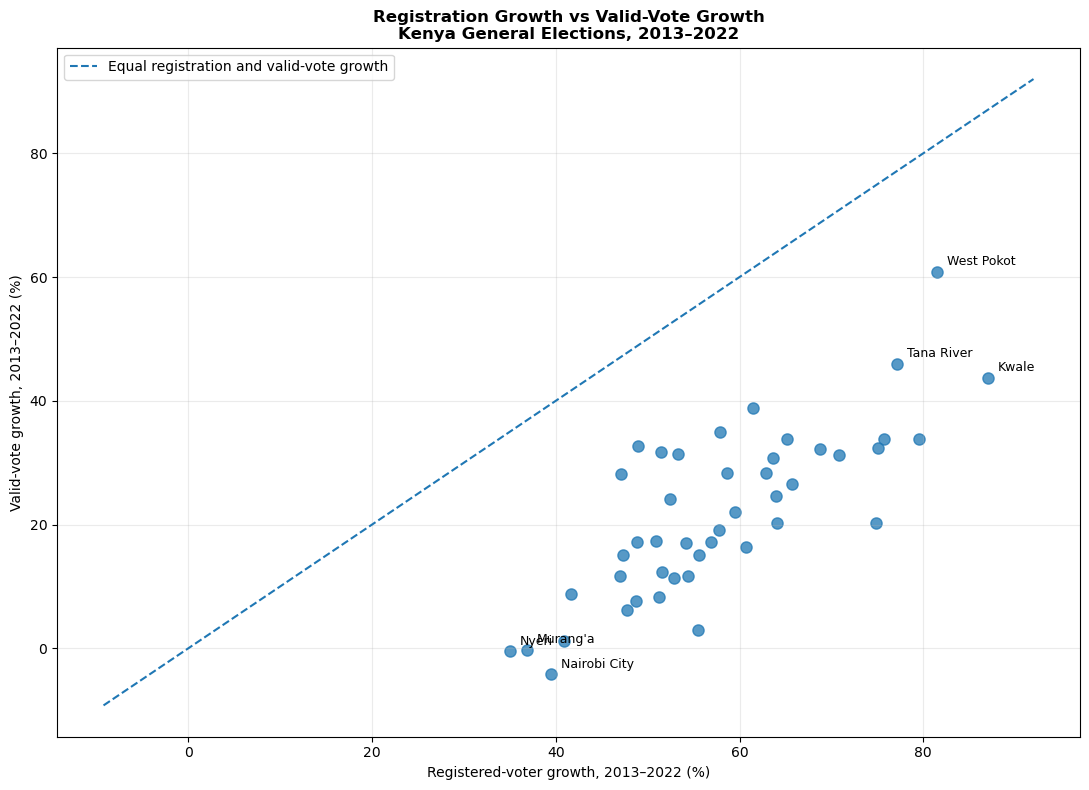

REGISTRATION AND VALID-VOTE GROWTH VISUALISATION
Counties analysed: 45
Counties where valid-vote growth was below registration growth: 45
Counties with declining absolute valid votes: 3
Validation: PASSED


In [91]:

# Notebook 04 — Cell 18
# Registration growth versus valid-vote growth, 2013–2022.
# Consistent 45-county sample.
# No existing files are modified.

import matplotlib.pyplot as plt
import numpy as np

plot_df = vote_growth_df.copy()

fig, ax = plt.subplots(figsize=(11, 8))

# Plot county registration growth against valid-vote growth.
ax.scatter(
    plot_df["registration_growth_pct"],
    plot_df["valid_vote_growth_pct"],
    s=65,
    alpha=0.75
)

# Equal-growth reference line.
line_min = min(
    plot_df["registration_growth_pct"].min(),
    plot_df["valid_vote_growth_pct"].min()
) - 5

line_max = max(
    plot_df["registration_growth_pct"].max(),
    plot_df["valid_vote_growth_pct"].max()
) + 5

ax.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
    linewidth=1.5,
    label="Equal registration and valid-vote growth"
)

# Label the three counties with declining valid-vote counts.
declining_counties = plot_df.loc[
    plot_df["valid_vote_growth_pct"] < 0
]

for _, row in declining_counties.iterrows():
    ax.annotate(
        row["county"],
        (
            row["registration_growth_pct"],
            row["valid_vote_growth_pct"]
        ),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=9
    )

# Highlight counties with the highest valid-vote growth.
highest_growth = (
    plot_df
    .nlargest(3, "valid_vote_growth_pct")
)

for _, row in highest_growth.iterrows():
    ax.annotate(
        row["county"],
        (
            row["registration_growth_pct"],
            row["valid_vote_growth_pct"]
        ),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Registered-voter growth, 2013–2022 (%)")
ax.set_ylabel("Valid-vote growth, 2013–2022 (%)")

ax.set_title(
    "Registration Growth vs Valid-Vote Growth\n"
    "Kenya General Elections, 2013–2022",
    fontweight="bold"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

print("REGISTRATION AND VALID-VOTE GROWTH VISUALISATION")
print("=" * 65)

print("Counties analysed:", len(plot_df))

below_equal_growth = (
    plot_df["valid_vote_growth_pct"]
    < plot_df["registration_growth_pct"]
).sum()

print(
    "Counties where valid-vote growth was below registration growth:",
    below_equal_growth
)

print(
    "Counties with declining absolute valid votes:",
    (plot_df["valid_vote_growth_pct"] < 0).sum()
)

assert len(plot_df) == 45
assert below_equal_growth == 45

print("Validation: PASSED")


### Interpretation of the scatter plot
**First**, registration growth exceeded valid-vote growth everywhere. This explains the universal decline in valid-vote participation rates across the comparable counties.

**Second**, most counties recorded increasing valid-vote counts. Forty-two counties appear above the horizontal zero-growth level, indicating that absolute valid votes increased even though participation rates declined.

**Third**, Nairobi City, Nyeri and Murang'a recorded declining valid-vote counts. Nairobi City's decline of 4.23% is substantially larger than the declines recorded in Nyeri and Murang'a.

West Pokot stands out with the highest valid-vote growth rate, while Kwale recorded the highest registration growth rate.

### What we have established in Notebook 04
Our exploratory analysis now supports five important findings:
| Research area | Finding | 
|--|--|
| Electoral registration	| The registered electorate expanded substantially between 2013 and 2022.|
| General-election participation	| Valid-vote participation declined in all 45 comparable counties.| 
| October 2017 fresh election	| Turnout declined in all 45 comparable counties, with pronounced differences in the magnitude of decline.| 
| County rankings	| Participation rankings remained strongly correlated across general elections, despite notable changes in individual counties.| 
| Registration versus voting	| Registered-voter growth exceeded valid-vote growth in all 45 comparable counties, although 42 recorded more valid votes in absolute terms.| 
|--|--|

These are descriptive findings. They do not establish the causes of declining participation.

**We also need to preserve our methodological qualifications: 2013 valid votes are ELOG-derived, August 2017 has two unresolved county records, and 2022 county figures remain independently unverified.**

### Final analytical consistency checks
Before closing this notebook, I recommend a final set of checks to ensure that the main findings are internally consistent.

We should not export our analytical summaries until these checks pass.

In [102]:

# Notebook 04 — Cell 19
# Final analytical consistency checks.
# Read-only validation; no files are created or modified.

import numpy as np
import pandas as pd

checks = []

def add_check(name, actual, expected):
    checks.append({
        "check": name,
        "actual": actual,
        "expected": expected,
        "status": "PASS" if actual == expected else "FAIL"
    })

# Dataset coverage
add_check(
    "Total election-county records",
    len(elections_df),
    188
)

add_check(
    "General-election comparison counties",
    len(general_comparable_df),
    45
)

add_check(
    "August–October 2017 comparable counties",
    len(classification_df),
    45
)

# General-election participation
add_check(
    "Counties with lower participation in 2022 than 2013",
    int((general_comparable_df["change_2013_2022_pp"] < 0).sum()),
    45
)

# Registration and valid-vote growth
add_check(
    "Counties with registration growth exceeding valid-vote growth",
    int((
        vote_growth_df["registration_growth_pct"]
        > vote_growth_df["valid_vote_growth_pct"]
    ).sum()),
    45
)

add_check(
    "Counties with increased valid votes",
    int((vote_growth_df["valid_vote_change_absolute"] > 0).sum()),
    42
)

add_check(
    "Counties with decreased valid votes",
    int((vote_growth_df["valid_vote_change_absolute"] < 0).sum()),
    3
)

# October 2017 turnout change
add_check(
    "Counties with declining August–October turnout",
    int((classification_df["turnout_change_pp"] < 0).sum()),
    45
)

# Confirm exclusion of October 2017 from general-election trends
add_check(
    "October 2017 excluded from general-election dataset",
    int((
        general_elections_df["election_id"]
        == "2017_OCT_FRESH"
    ).sum()),
    0
)

# Check the aggregate growth comparison.
registration_growth_aggregate = (
    (
        vote_growth_df["registered_2022"].sum()
        / vote_growth_df["registered_2013"].sum()
    ) - 1
) * 100

valid_vote_growth_aggregate = (
    (
        vote_growth_df["valid_votes_2022"].sum()
        / vote_growth_df["valid_votes_2013"].sum()
    ) - 1
) * 100

checks.append({
    "check": "Aggregate registration growth exceeds valid-vote growth",
    "actual": round(registration_growth_aggregate, 2),
    "expected": f"> {valid_vote_growth_aggregate:.2f}",
    "status": (
        "PASS"
        if registration_growth_aggregate > valid_vote_growth_aggregate
        else "FAIL"
    )
})

# Produce final validation register.
notebook04_validation = pd.DataFrame(checks)

print("NOTEBOOK 04 — FINAL ANALYTICAL VALIDATION")
print("=" * 65)

#display(notebook04_validation)
# Display complete validation check descriptions without truncation
with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None,
    "display.width", 1000
):
    display(
        notebook04_validation.style.set_properties(
            subset=["check"],
            **{
                "text-align": "left",
                "white-space": "normal",
                "min-width": "450px"
            }
        )
    )

print("\nVALIDATION SUMMARY")

display(
    notebook04_validation["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="checks")
)

assert notebook04_validation["status"].eq("PASS").all(), (
    "One or more analytical validation checks failed."
)

print("\nAll Notebook 04 analytical checks: PASSED")


NOTEBOOK 04 — FINAL ANALYTICAL VALIDATION


,check,actual,expected,status
0,Total election-county records,188.000000,188,PASS
1,General-election comparison counties,45.000000,45,PASS
2,August–October 2017 comparable counties,45.000000,45,PASS
3,Counties with lower participation in 2022 than 2013,45.000000,45,PASS
4,Counties with registration growth exceeding valid-vote growth,45.000000,45,PASS
5,Counties with increased valid votes,42.000000,42,PASS
6,Counties with decreased valid votes,3.000000,3,PASS
7,Counties with declining August–October turnout,45.000000,45,PASS
8,October 2017 excluded from general-election dataset,0.000000,0,PASS
9,Aggregate registration growth exceeds valid-vote growth,53.360000,> 15.82,PASS



VALIDATION SUMMARY


,status,checks
0,PASS,10



All Notebook 04 analytical checks: PASSED


### Save final analytical outputs
| File	| Purpose|
|--|--|
| notebook04_validation_summary.csv	| Final validation results| 
| notebook04_key_findings.csv	| Main quantitative findings| 
| notebook04_analysis_summary.md	| Narrative summary, interpretation and limitations| 

In [107]:

# ================================================================
# NOTEBOOK 04 — CELL 20
# SAVE FINAL ANALYTICAL FINDINGS AND VALIDATION DOCUMENTATION
# ================================================================
# Purpose:
# 1. Save the final Notebook 04 validation results.
# 2. Save the main quantitative findings.
# 3. Create a Markdown summary of findings and limitations.
# 4. Verify that all documentation files were saved correctly.
#
# Existing source datasets will not be modified.
# Existing documentation files will not be overwritten.
# ================================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------
# STEP 1: ESTABLISH PROJECT DIRECTORIES
# ------------------------------------------------

# Define the analytical dataset location explicitly.
# This resolves the previous NameError involving DATA_PATH.

DATA_PATH = (
    Path(
        r"C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project"
    )
    / "data"
    / "processed"
    / "kenya_county_election_analytics.csv"
)

# Confirm that the analytical dataset exists.
assert DATA_PATH.is_file(), (
    f"Analytical dataset not found: {DATA_PATH}"
)

# Navigate from the CSV file to the project root.
# CSV -> processed -> data -> project root
project_root = DATA_PATH.parent.parent.parent

# Define the documentation directory.
docs_dir = project_root / "documentation"

assert docs_dir.is_dir(), (
    f"Documentation directory not found: {docs_dir}"
)

print("PROJECT DIRECTORIES VERIFIED")
print("=" * 65)
print("Project root:", project_root)
print("Documentation directory:", docs_dir)


# ------------------------------------------------
# STEP 2: VERIFY NOTEBOOK 04 VALIDATION RESULTS
# ------------------------------------------------

assert len(notebook04_validation) == 10, (
    "Expected 10 final validation checks."
)

assert notebook04_validation["status"].eq("PASS").all(), (
    "One or more Notebook 04 validation checks failed."
)

assert len(general_comparable_df) == 45, (
    "Expected 45 comparable counties."
)

assert len(vote_growth_df) == 45, (
    "Expected 45 counties in the growth analysis."
)


# ------------------------------------------------
# STEP 3: DEFINE OUTPUT FILE PATHS
# ------------------------------------------------

validation_path = (
    docs_dir / "notebook04_validation_summary.csv"
)

findings_path = (
    docs_dir / "notebook04_key_findings.csv"
)

summary_path = (
    docs_dir / "notebook04_analysis_summary.md"
)

# Prevent accidental overwriting of existing files.
for path in [
    validation_path,
    findings_path,
    summary_path
]:
    assert not path.exists(), (
        f"Output file already exists: {path}"
    )


# ------------------------------------------------
# STEP 4: PREPARE QUANTITATIVE FINDINGS
# ------------------------------------------------

key_findings = pd.DataFrame([
    {
        "finding": "Comparable counties",
        "value": 45,
        "unit": "counties"
    },
    {
        "finding": "Counties with declining valid-vote participation",
        "value": int(
            (
                general_comparable_df[
                    "change_2013_2022_pp"
                ] < 0
            ).sum()
        ),
        "unit": "counties"
    },
    {
        "finding": "Mean county participation decline, 2013-2022",
        "value": round(
            -general_comparable_df[
                "change_2013_2022_pp"
            ].mean(),
            2
        ),
        "unit": "percentage points"
    },
    {
        "finding": "Aggregate registration growth, 2013-2022",
        "value": round(
            registration_growth_aggregate,
            2
        ),
        "unit": "percent"
    },
    {
        "finding": "Aggregate valid-vote growth, 2013-2022",
        "value": round(
            valid_vote_growth_aggregate,
            2
        ),
        "unit": "percent"
    },
    {
        "finding": "Counties with increased absolute valid votes",
        "value": int(
            (
                vote_growth_df[
                    "valid_vote_change_absolute"
                ] > 0
            ).sum()
        ),
        "unit": "counties"
    },
    {
        "finding": "Counties with decreased absolute valid votes",
        "value": int(
            (
                vote_growth_df[
                    "valid_vote_change_absolute"
                ] < 0
            ).sum()
        ),
        "unit": "counties"
    },
    {
        "finding": "Counties with declining August-October 2017 turnout",
        "value": int(
            (
                classification_df[
                    "turnout_change_pp"
                ] < 0
            ).sum()
        ),
        "unit": "counties"
    },
    {
        "finding": "Pearson correlation: registration growth vs participation change",
        "value": round(
            pearson_correlation,
            3
        ),
        "unit": "correlation coefficient"
    },
    {
        "finding": "Spearman correlation: registration growth vs participation change",
        "value": round(
            spearman_correlation,
            3
        ),
        "unit": "correlation coefficient"
    }
])


# ------------------------------------------------
# STEP 5: CREATE METHODOLOGY AND FINDINGS SUMMARY
# ------------------------------------------------

summary_text = f"""# Notebook 04 — Electoral Participation Exploratory Analysis

## 1. Scope

This notebook analyses electoral participation across Kenya's
47 counties for four presidential election events:

- 2013 General Election
- August 2017 General Election
- October 2017 Fresh Presidential Election
- 2022 General Election

The longitudinal general-election comparison uses a consistent
sample of 45 counties.

Kisumu and Turkana are excluded from analyses requiring
validated August 2017 participation figures.

## 2. Main Findings

### 2.1 General-election participation

All 45 comparable counties recorded lower valid-vote
participation in 2022 than in 2013.

Mean county valid-vote participation declined by
{-general_comparable_df["change_2013_2022_pp"].mean():.2f}
percentage points between 2013 and 2022.

### 2.2 Registered-voter growth

Aggregate registered-voter counts increased by
{registration_growth_aggregate:.2f}%
between 2013 and 2022 across the 45 comparable counties.

### 2.3 Valid-vote growth

Aggregate valid-vote counts increased by
{valid_vote_growth_aggregate:.2f}%
over the same period.

Absolute valid-vote counts increased in 42 counties.

Three counties recorded declining valid-vote counts:

- Nairobi City
- Nyeri
- Murang'a

### 2.4 October 2017 fresh presidential election

All 45 counties with comparable August and October
2017 turnout data experienced declining turnout.

The magnitude of the decline varied considerably
between counties.

The October 2017 election is analysed separately
from ordinary general elections.

### 2.5 County participation rankings

County participation rankings remained positively
correlated across the three general elections.

Some counties improved their relative rankings
despite recording lower participation rates.

### 2.6 Registration growth and participation

The relationship between county registration growth
and participation change was:

- Pearson correlation: {pearson_correlation:.3f}
- Spearman correlation: {spearman_correlation:.3f}

These associations are descriptive and do not
establish causation.

## 3. Interpretation

Registered-voter growth exceeded valid-vote growth
across all 45 comparable counties.

Consequently, declining valid-vote participation
rates did not necessarily correspond to declining
absolute valid-vote counts.

The analysis demonstrates the importance of
examining registration, participation rates and
absolute voting volumes together.

## 4. Methodological Limitations

1. The 2013 valid-vote figures are ELOG-derived,
   while registered-voter denominators use IEBC data.

2. August 2017 contains two unresolved county
   records: Kisumu and Turkana.

3. The October 2017 fresh presidential election
   is treated as a distinct electoral event.

4. The 2022 county figures are ELOG-derived and
   have not been independently reconciled against
   official county-level data.

5. Valid-vote participation is not identical to
   electoral turnout because rejected ballots
   are excluded.

6. Correlation analysis is descriptive and
   does not demonstrate causal relationships.

7. Results based on 45 counties should not
   be presented as complete national estimates.

## 5. Validation

Notebook 04 completed
{len(notebook04_validation)} analytical validation checks.

All checks returned PASS.

## 6. Next Stage

Notebook 05 — Electoral Participation
Visualisation and Reporting.

The next notebook will focus on:

- Publication-quality visualisations
- County-level participation comparisons
- National and county analytical summaries
- Documentation of source limitations
- Development of a coherent research narrative
"""


# ------------------------------------------------
# STEP 6: SAVE DOCUMENTATION FILES
# ------------------------------------------------

notebook04_validation.to_csv(
    validation_path,
    index=False
)

key_findings.to_csv(
    findings_path,
    index=False
)

summary_path.write_text(
    summary_text,
    encoding="utf-8"
)


# ------------------------------------------------
# STEP 7: VERIFY SAVED OUTPUTS
# ------------------------------------------------

saved_validation = pd.read_csv(validation_path)
saved_findings = pd.read_csv(findings_path)
saved_summary = summary_path.read_text(
    encoding="utf-8"
)

assert saved_validation.shape == notebook04_validation.shape, (
    "Validation summary verification failed."
)

assert saved_findings.shape == key_findings.shape, (
    "Key findings verification failed."
)

assert saved_summary == summary_text, (
    "Markdown summary verification failed."
)

assert saved_validation["status"].eq("PASS").all(), (
    "Saved validation file contains failed checks."
)


# ------------------------------------------------
# STEP 8: DISPLAY FINAL EXPORT CONFIRMATION
# ------------------------------------------------

print("\nNOTEBOOK 04 — DOCUMENTATION EXPORT COMPLETE")
print("=" * 65)

print("\nFILES SAVED:")

for path in [
    validation_path,
    findings_path,
    summary_path
]:
    print(f"Saved: {path}")

print("\nFINAL VERIFICATION")

print(
    "Validation checks:",
    len(saved_validation)
)

print(
    "All checks passed:",
    saved_validation["status"].eq("PASS").all()
)

print(
    "Key findings documented:",
    len(saved_findings)
)

print(
    "Methodology summary characters:",
    len(saved_summary)
)

print("\nDocumentation verification: PASSED")


PROJECT DIRECTORIES VERIFIED
Project root: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project
Documentation directory: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation

NOTEBOOK 04 — DOCUMENTATION EXPORT COMPLETE

FILES SAVED:
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation\notebook04_validation_summary.csv
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation\notebook04_key_findings.csv
Saved: C:\Users\user\Downloads\Kenya Electoral Participation Analytics Project\documentation\notebook04_analysis_summary.md

FINAL VERIFICATION
Validation checks: 10
All checks passed: True
Key findings documented: 10
Methodology summary characters: 3451

Documentation verification: PASSED
